# Análisis No Supervisado — Perfiles de Riesgo en Dengue
## Bucaramanga 2015–2025 · 28,626 casos · DCSA + DSSA

---

## Por qué clustering después del modelado supervisado

Los notebooks 03a–03d revelaron que los modelos supervisados alcanzan
el techo informativo de los features SIVIGILA disponibles:
Extra Trees DCSA logra F1=0.800 y Extra Trees DSSA alcanza AUC-PR=0.096.
Antes de concluir que 'los datos no tienen más información',
el clustering permite preguntarse: **¿existen grupos naturales de pacientes
que los modelos supervisados no pudieron capturar?**

El análisis no supervisado complementa al supervisado de tres formas:

1. **Descubrimiento:** identifica subgrupos de pacientes sin usar la etiqueta
   de hospitalización — puede revelar perfiles clínicos que el médico
   reconoce pero que no están explícitos en el formulario SIVIGILA.
2. **Validación:** si los clusters se alinean con la variable de hospitalización,
   confirma que los features tienen estructura real. Si no se alinean,
   sugiere que la señal clínica disponible es insuficiente para segmentar.
3. **Contexto para equidad:** los perfiles demográficos de cada cluster
   revelan si la estructura de los datos refleja patrones epidemiológicos
   reales o inequidades de acceso al sistema de salud.

## Decisiones metodológicas basadas en los resultados del módulo 03

| Decisión | Justificación |
|----------|---------------|
| Analizar DCSA y DSSA por separado | Los dos estratos tienen naturalezas radicalmente distintas (64.8% vs 3.9% hosp.) — mezclarlos distorsionaría los clusters |
| Features clínicos + demográficos, sin AÑO | Consistente con 03a–03c: AÑO introduce sesgo de período |
| PCA antes de clustering | 24 features con correlaciones (MALGIAS–ARTRALGIA, etc.) — reducir dimensionalidad mejora la separación |
| K-Means + clustering jerárquico | K-Means para explorar k óptimo; jerárquico para visualizar estructura sin asumir k |
| Validar con hospitalización | La etiqueta supervisada valida si los clusters tienen significado clínico |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
import joblib
import gc
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Instalar kmodes y umap si no están disponibles
import importlib, subprocess, sys
for pkg, imp in [('kmodes','kmodes'), ('umap-learn','umap'), ('hdbscan','hdbscan')]:
    if importlib.util.find_spec(imp) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg])
from kmodes.kprototypes import KPrototypes
import umap
import hdbscan

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'legend.frameon': False,
})
COLORS = {
    'primary': '#2C7BB6', 'secondary': '#D7191C',
    'accent': '#FDAE61', 'neutral': '#7F7F7F',
    'con_signos': '#E74C3C', 'sin_signos': '#3498DB',
}
PALETA_CLUSTERS = ['#E74C3C','#3498DB','#2ECC71','#F39C12','#9B59B6','#1ABC9C']

SIGNOS_ALARMA      = ['DOLOR_ABDO','VOMITO','DIARREA','SOMNOLENCI','HIPOTENSIO',
                      'HEPATOMEG','HEM_MUCOSA','HIPOTERMIA','AUM_HEMATO','CAIDA_PLAQ','ACUM_LIQUI']
SINTOMAS_GENERALES = ['FIEBRE','CEFALEA','DOLRRETROO','MALGIAS','ARTRALGIA','ERUPCIONR']
TARGET             = 'TARGET_HOSPITALIZACION_ORIGINAL'
RANDOM_STATE       = 42

ROOT        = Path(r'D:\Documentos\GitHub\dengue')
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'
for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)

def limpiar_memoria(*objetos):
    for obj in objetos:
        try: del obj
        except: pass
    gc.collect()

def memoria_usada():
    import psutil, os
    mb = psutil.Process(os.getpid()).memory_info().rss / 1e6
    print(f'  RAM en uso: {mb:.0f} MB')

df_con = joblib.load(INTERIM / 'datos_con_signos.pkl')
df_sin = joblib.load(INTERIM / 'datos_sin_signos.pkl')
print(f'DCSA: {len(df_con):,} casos | Hosp: {df_con[TARGET].mean():.1%}')
print(f'DSSA: {len(df_sin):,} casos | Hosp: {df_sin[TARGET].mean():.1%}')

DCSA: 12,713 casos | Hosp: 64.8%
DSSA: 15,734 casos | Hosp: 3.9%


## 1. Preparación de datos para clustering

El clustering trabaja sobre el espacio de features clínicos y demográficos —
los mismos 24 variables usados en los modelos supervisados, sin AÑO.
Se aplica el mismo preprocesamiento que en 03a/03c para mantener
consistencia metodológica: imputación por mediana y estandarización.

Los algoritmos de clustering basados en distancias (K-Means, jerárquico)
son sensibles a la escala de las variables y a la dimensionalidad.
Con 24 features y correlaciones entre síntomas (MALGIAS–ARTRALGIA,
FIEBRE–CEFALEA), el PCA previo reduce el ruido y mejora la separación.

In [2]:
def preparar_para_clustering(df):
    """Preprocesa un estrato para clustering.
    Devuelve:
    - X_sc      : features escalados (para K-Means, PCA, GMM)
    - X_mixto   : features sin escalar con tipos originales (para K-Prototypes)
    - df_m      : DataFrame con target
    - features  : lista de nombres
    - idx_cat   : índices de columnas binarias (para K-Prototypes)
    """
    vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
    vars_demo     = [v for v in ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_','GP_GESTAN','GRUPO_ETARIO']
                     if v in df.columns]
    vars_tiempo   = [v for v in ['SEMANA'] if v in df.columns]
    features      = vars_clinicas + vars_demo + vars_tiempo

    df_m = df[features + [TARGET]].copy()
    for v in vars_clinicas:
        df_m[v] = df_m[v].map({1: 1, 2: 0})
    for v in vars_demo:
        if str(df_m[v].dtype) in ('object',) or str(df_m[v].dtype).startswith('string'):
            df_m[v] = pd.Categorical(df_m[v]).codes.astype(float)
            df_m[v] = df_m[v].replace(-1, np.nan)
    for col in features:
        df_m[col] = pd.to_numeric(df_m[col], errors='coerce').astype(np.float64)

    imp    = SimpleImputer(strategy='median')
    X      = imp.fit_transform(df_m[features])
    scaler = StandardScaler()
    X_sc   = scaler.fit_transform(X)

    # Índices de columnas binarias — necesario para K-Prototypes
    # K-Prototypes trata estas columnas con distancia de Hamming
    idx_cat = list(range(len(vars_clinicas)))  # síntomas son todas binarias

    return X_sc, X, df_m, features, idx_cat

X_con, X_con_raw, df_con_m, features_con, idx_cat_con = preparar_para_clustering(df_con)
X_sin, X_sin_raw, df_sin_m, features_sin, idx_cat_sin = preparar_para_clustering(df_sin)
print(f'DCSA listo: {X_con.shape} | Variables binarias: {len(idx_cat_con)}')
print(f'DSSA listo: {X_sin.shape} | Variables binarias: {len(idx_cat_sin)}')

DCSA listo: (12713, 20) | Variables binarias: 17
DSSA listo: (15734, 20) | Variables binarias: 17


## 2. Reducción de dimensionalidad con PCA

El PCA transforma los 24 features originales en componentes ortogonales
ordenados por varianza explicada. Antes de definir cuántos componentes
retener, se analiza la varianza acumulada para elegir el umbral mínimo
que preserve al menos el 80% de la información.

Las primeras dos componentes permiten visualizar la estructura de los datos
en 2D — fundamental para interpretar los clusters.
Las componentes adicionales mejoran el clustering aunque no sean visualizables.

Un umbral del 80% de varianza es conservador en datos clínicos binarios:
los síntomas tienen correlaciones moderadas y no colapsan en pocos factores.

DCSA — con signos de alarma: 13 componentes para 80% varianza | 15 para 90%
DSSA — sin signos de alarma: 10 componentes para 80% varianza | 12 para 90%


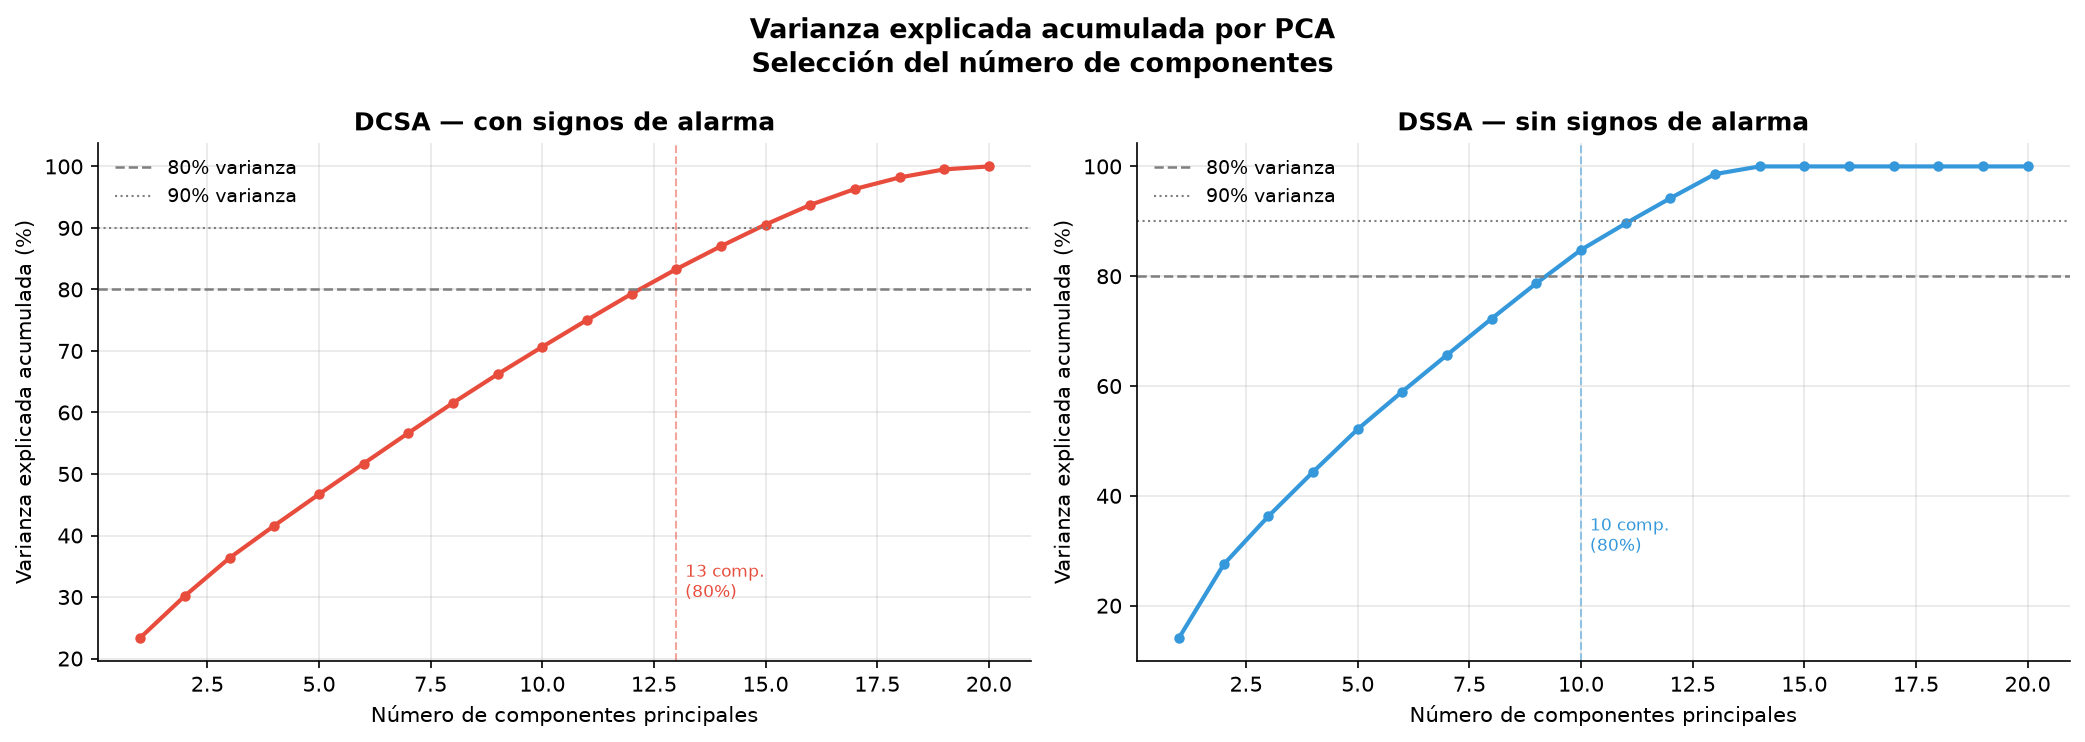

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, X, titulo, color in zip(
    axes,
    [X_con, X_sin],
    ['DCSA — con signos de alarma', 'DSSA — sin signos de alarma'],
    [COLORS['con_signos'], COLORS['sin_signos']]
):
    pca_full = PCA(random_state=RANDOM_STATE)
    pca_full.fit(X)
    var_acum = np.cumsum(pca_full.explained_variance_ratio_) * 100

    ax.plot(range(1, len(var_acum)+1), var_acum,
        color=color, linewidth=2, marker='o', markersize=4)
    ax.axhline(80, color=COLORS['neutral'], linestyle='--', linewidth=1.2,
        label='80% varianza')
    ax.axhline(90, color=COLORS['neutral'], linestyle=':', linewidth=1,
        label='90% varianza')

    n80 = np.argmax(var_acum >= 80) + 1
    n90 = np.argmax(var_acum >= 90) + 1
    ax.axvline(n80, color=color, linestyle='--', linewidth=1, alpha=0.5)
    ax.text(n80+0.2, 30, f'{n80} comp.\n(80%)', fontsize=8, color=color)

    ax.set_xlabel('Número de componentes principales')
    ax.set_ylabel('Varianza explicada acumulada (%)')
    ax.set_title(titulo)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    print(f'{titulo}: {n80} componentes para 80% varianza | {n90} para 90%')

plt.suptitle('Varianza explicada acumulada por PCA\nSelección del número de componentes',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_pca_varianza.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

DCSA — varianza explicada con 13 componentes: 83.3%
DSSA — varianza explicada con 13 componentes: 98.6%


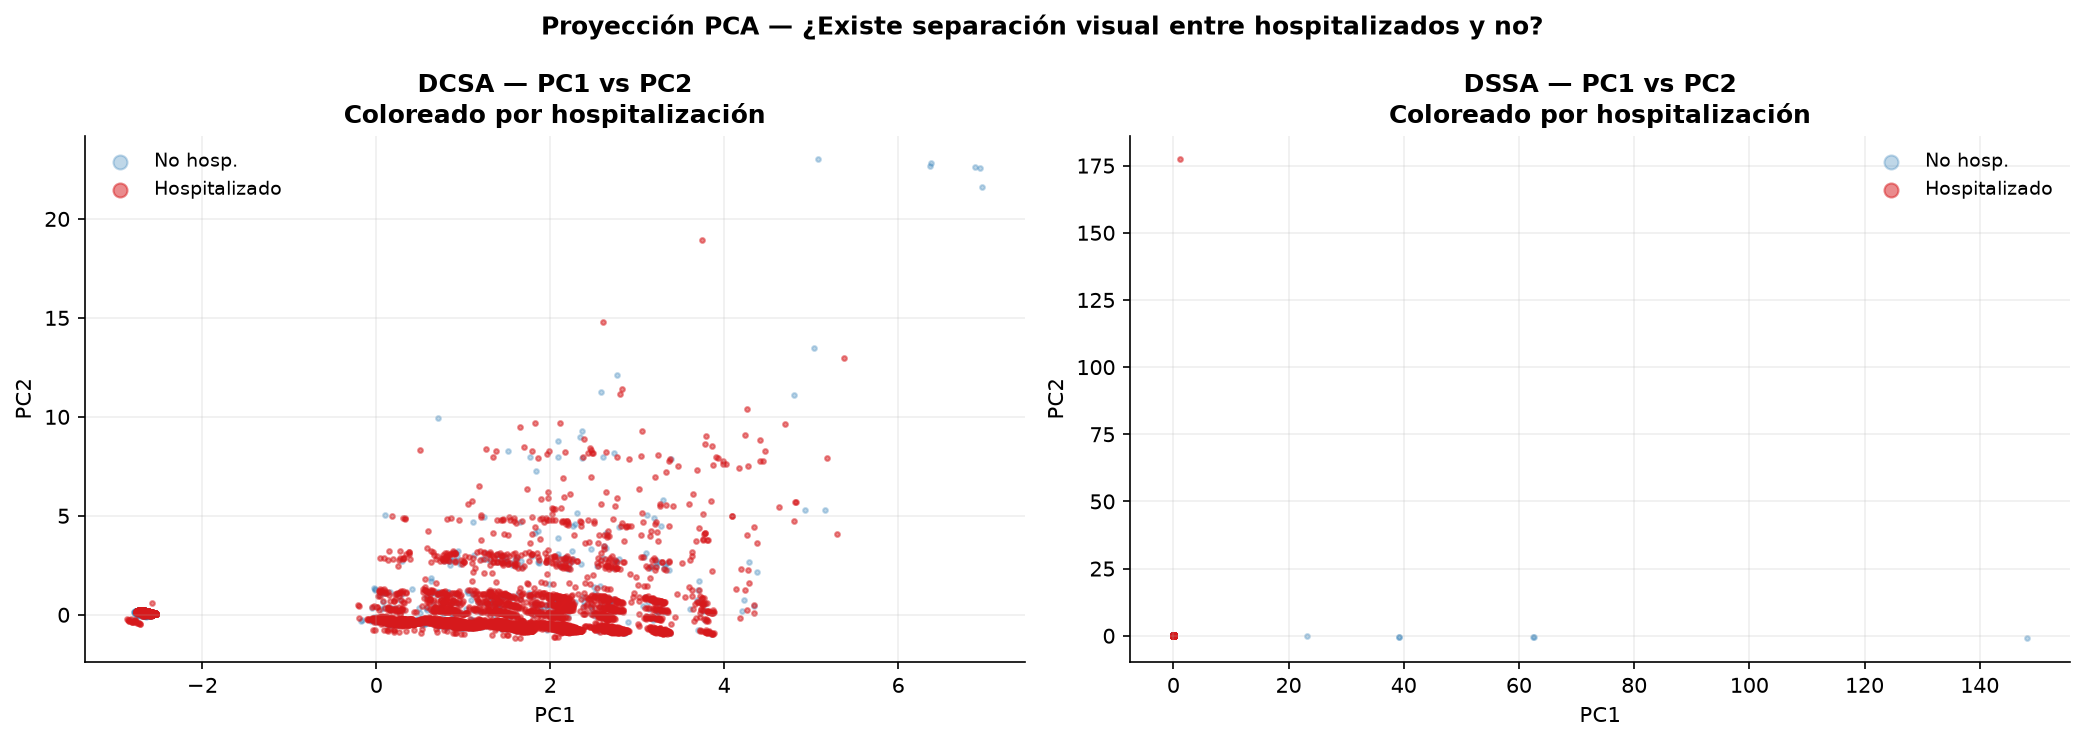

In [4]:
# Aplicar PCA con el número de componentes que explica 80% de varianza
# Se usa el mismo umbral en ambos estratos para comparabilidad
N_COMPONENTES = 13  # ajustar según la gráfica anterior

pca_con = PCA(n_components=N_COMPONENTES, random_state=RANDOM_STATE)
pca_sin = PCA(n_components=N_COMPONENTES, random_state=RANDOM_STATE)

X_con_pca = pca_con.fit_transform(X_con)
X_sin_pca = pca_sin.fit_transform(X_sin)

print(f'DCSA — varianza explicada con {N_COMPONENTES} componentes: '
      f'{pca_con.explained_variance_ratio_.sum()*100:.1f}%')
print(f'DSSA — varianza explicada con {N_COMPONENTES} componentes: '
      f'{pca_sin.explained_variance_ratio_.sum()*100:.1f}%')

# Visualización de los dos primeros componentes coloreados por hospitalización
# Si hay separación visual → los features tienen poder discriminativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, X_pca, df_m, titulo in zip(
    axes,
    [X_con_pca, X_sin_pca],
    [df_con_m, df_sin_m],
    ['DCSA', 'DSSA']
):
    hosp = df_m[TARGET].values
    for val, label, color, alpha in [
        (0, 'No hosp.', COLORS['primary'], 0.3),
        (1, 'Hospitalizado', COLORS['secondary'], 0.5)
    ]:
        mask = hosp == val
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
            c=color, alpha=alpha, s=5, label=label, rasterized=True)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_title(f'{titulo} — PC1 vs PC2\nColoreado por hospitalización')
    ax.legend(fontsize=9, markerscale=3)
    ax.grid(alpha=0.2)

plt.suptitle('Proyección PCA — ¿Existe separación visual entre hospitalizados y no?',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_pca_proyeccion.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 3. Selección del número óptimo de clusters — DCSA

Se usan tres criterios complementarios:

- **Inertia (codo):** busca el punto donde añadir un cluster reduce poco la varianza intra-cluster.
- **Silhouette Score:** mide qué tan bien separados están los clusters (↑ mejor, máximo 1.0).
- **Davies-Bouldin:** penaliza clusters grandes y poco separados (↓ mejor).

### Resultados de la selección de k — DCSA

Las métricas muestran que **k=3 maximiza el Silhouette (0.427)**,
aunque k=2 tiene Silhouette similar (0.404) con mejor Davies-Bouldin (0.969).
El codo se observa entre k=2 y k=3 — ambos son candidatos válidos.

Se elige **k=3** para explorar si existe un tercer perfil clínico diferenciado,
sabiendo que k=2 es la estructura más robusta estadísticamente.

Evaluando K-Means para DCSA...
  k=2: Silhouette=0.375 DB=1.157
  k=3: Silhouette=0.393 DB=1.067
  k=4: Silhouette=0.409 DB=0.938
  k=5: Silhouette=0.306 DB=1.599
  k=6: Silhouette=0.325 DB=1.418
  k=7: Silhouette=0.348 DB=1.265
  k=8: Silhouette=0.364 DB=1.176


,k,Inertia,Silhouette,Davies-Bouldin,Calinski
0,2,158656.7,0.3753,1.1566,4256.2
1,3,145619.3,0.3932,1.0675,2887.4
2,4,133328.1,0.4094,0.9382,2492.8
3,5,122692.5,0.3060,1.5988,2306.9
4,6,111096.8,0.3249,1.4180,2303.3
5,7,100500.7,0.3479,1.2648,2344.8
6,8,90579.1,0.3635,1.1760,2428.6


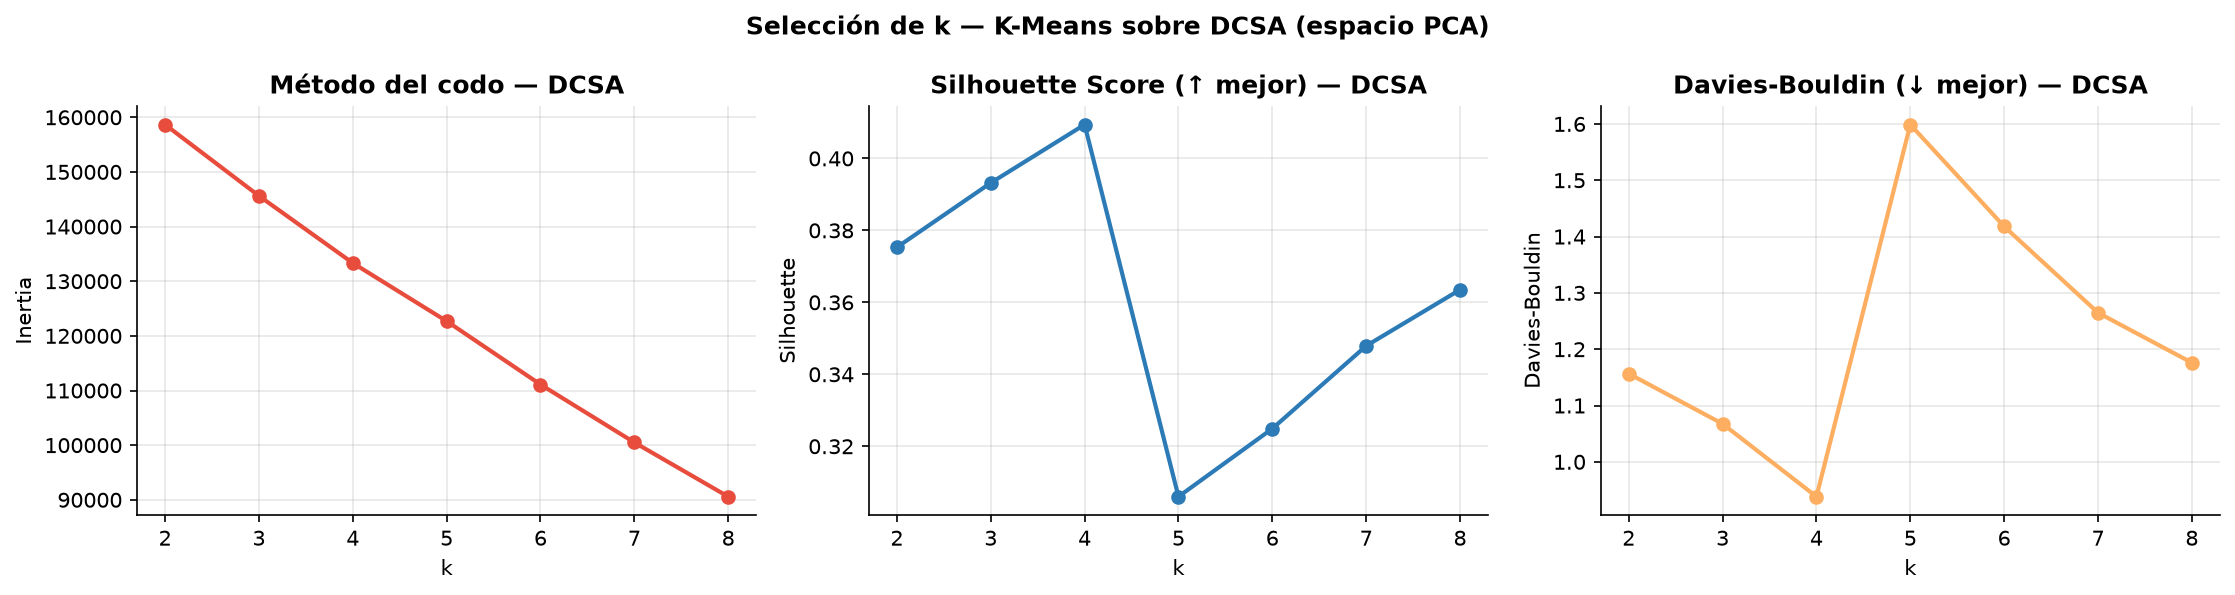

In [5]:
def evaluar_kmeans(X, k_range=range(2, 9), nombre=''):
    """Calcula métricas de validación para un rango de k.
    En DSSA los datos están muy concentrados en el espacio PCA —
    K-Means puede colapsar en un solo cluster para k pequeños.
    El Silhouette se calcula siempre con submuestreo manual
    para evitar el bug de sklearn con sample_size.
    """
    n = len(X)
    resultados = []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE,
                    n_init=15, max_iter=500)
        labels = km.fit_predict(X)
        n_labels = len(set(labels))
        if n_labels < 2:
            print(f'  k={k}: K-Means colapsó en 1 cluster — omitiendo')
            continue

        # Submuestreo manual garantizando al menos 10 puntos por cluster
        idx_list = []
        for lbl in set(labels):
            idx_lbl = np.where(labels == lbl)[0]
            idx_list.append(np.random.choice(
                idx_lbl, min(300, len(idx_lbl)), replace=False))
        idx_sil  = np.concatenate(idx_list)
        X_sil    = X[idx_sil]
        lbl_sil  = labels[idx_sil]

        try:
            sil = silhouette_score(X_sil, lbl_sil)
        except Exception:
            sil = float('nan')

        resultados.append({
            'k':              k,
            'Inertia':        round(km.inertia_, 1),
            'Silhouette':     round(sil, 4) if not (sil != sil) else None,
            'Davies-Bouldin': round(davies_bouldin_score(X, labels), 4),
            'Calinski':       round(calinski_harabasz_score(X, labels), 1),
        })
        print(f'  k={k}: Silhouette={sil:.3f} '
              f'DB={resultados[-1]["Davies-Bouldin"]:.3f}')

    df_res = pd.DataFrame(resultados)
    df_res.to_csv(OUT_TAB / f'clustering_metricas_{nombre}.csv', index=False)
    return df_res

print('Evaluando K-Means para DCSA...')
metricas_con = evaluar_kmeans(X_con_pca, nombre='DCSA')
display(metricas_con)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(metricas_con['k'], metricas_con['Inertia'],
    color=COLORS['con_signos'], linewidth=2, marker='o', markersize=6)
axes[0].set_title('Método del codo — DCSA')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)
axes[1].plot(metricas_con['k'], metricas_con['Silhouette'],
    color=COLORS['primary'], linewidth=2, marker='o', markersize=6)
axes[1].set_title('Silhouette Score (↑ mejor) — DCSA')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
axes[1].grid(alpha=0.3)
axes[2].plot(metricas_con['k'], metricas_con['Davies-Bouldin'],
    color=COLORS['accent'], linewidth=2, marker='o', markersize=6)
axes[2].set_title('Davies-Bouldin (↓ mejor) — DCSA')
axes[2].set_xlabel('k'); axes[2].set_ylabel('Davies-Bouldin')
axes[2].grid(alpha=0.3)
plt.suptitle('Selección de k — K-Means sobre DCSA (espacio PCA)',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dcsa_seleccion_k.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 4. K-Means final — DCSA

Con k=3 se ajusta el K-Means final y se valida clínicamente cada cluster
por su tasa de hospitalización y perfil de síntomas.

### ⚠️ Hallazgo: Cluster 1 es un subgrupo atípico

Los resultados revelan una estructura asimétrica:

| Cluster | N | Hosp. | Perfil |
|---------|---|-------|--------|
| 0 | 7,676 | **80.8%** | Alta prevalencia síntomas generales — perfil clínico completo |
| 1 | 320 | 78.1% | Similar al 0 pero muy pequeño — posible subgrupo atípico |
| 2 | 4,717 | **38.0%** | FIEBRE=0, todos los síntomas=0 — formularios incompletos |

**El Cluster 2 es el hallazgo más relevante clínicamente:**
con FIEBRE=0.0 y todos los síntomas en 0, corresponde a pacientes
con formularios SIVIGILA incompletos — no a pacientes sin síntomas.
Esto confirma el hallazgo del 03b: antes de 2022 muchos campos
quedaban en blanco. El 38% de hospitalización en este cluster
refleja casos clasificados como DCSA sin registro de síntomas.

**El Cluster 1 (n=320, 78.1% hosp.)** es casi idéntico al Cluster 0
en tasa de hospitalización — los diferencia principalmente DOLOR_ABDO
y VOMITO con mayor prevalencia. Es un subgrupo dentro del perfil de
alta hospitalización, no un cluster verdaderamente distinto.

> La estructura natural de DCSA parece ser **k=2**: formularios completos
> (alta hospitalización) vs incompletos (hospitalización moderada).
> Esta es una limitación metodológica importante — el clustering captura
> la calidad del registro tanto como los perfiles clínicos reales.

Caracterización de clusters DCSA:


,N,Hosp_pct,FIEBRE,CEFALEA,DOLRRETROO,MALGIAS,ARTRALGIA,ERUPCIONR,DOLOR_ABDO,VOMITO
Cluster,,,,,,,,,,
1,126,84.1,1.0,0.762,0.421,0.857,0.738,0.413,0.635,0.325
2,7870,80.6,1.0,0.827,0.461,0.868,0.706,0.315,0.522,0.337
0,4717,38.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000


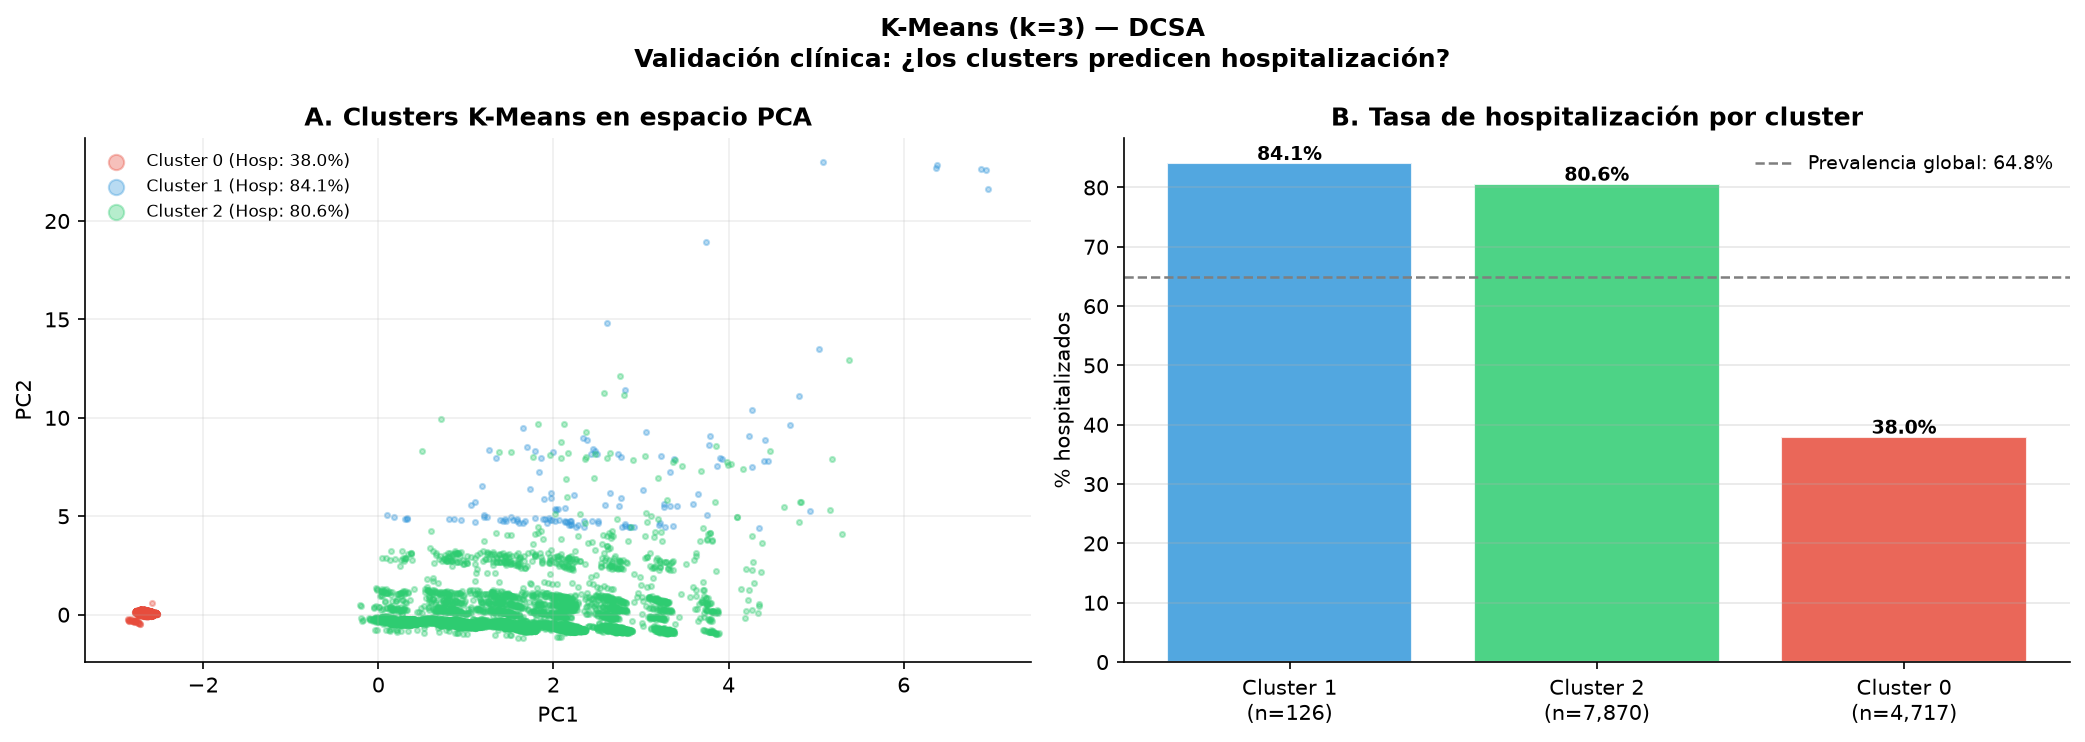

In [6]:
# Ajustar k según lo observado en las métricas de la celda anterior
K_DCSA = 3  # ajustar según las gráficas

km_con = KMeans(n_clusters=K_DCSA, random_state=RANDOM_STATE, n_init=10)
df_con_m['Cluster'] = km_con.fit_predict(X_con_pca)

# Tabla de caracterización por cluster
# Tasa de hospitalización — validación del significado clínico
vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
vars_demo     = [v for v in ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_'] if v in df_con_m.columns]

tabla_clusters = df_con_m.groupby('Cluster').agg(
    N=(TARGET, 'size'),
    Hosp_pct=(TARGET, 'mean'),
    **{v: (v, 'mean') for v in vars_clinicas if v in df_con_m.columns}
).round(3)
tabla_clusters['Hosp_pct'] = (tabla_clusters['Hosp_pct']*100).round(1)
tabla_clusters = tabla_clusters.sort_values('Hosp_pct', ascending=False)

print('Caracterización de clusters DCSA:')
display(tabla_clusters[['N','Hosp_pct'] + vars_clinicas[:8]])
tabla_clusters.to_csv(OUT_TAB / 'clustering_dcsa_perfiles.csv')

# Visualización en espacio PCA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: clusters en PC1-PC2
for k in range(K_DCSA):
    mask = df_con_m['Cluster'] == k
    hosp_k = df_con_m.loc[mask, TARGET].mean()
    axes[0].scatter(
        X_con_pca[mask, 0], X_con_pca[mask, 1],
        c=PALETA_CLUSTERS[k], alpha=0.35, s=6,
        label=f'Cluster {k} (Hosp: {hosp_k:.1%})', rasterized=True)
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('A. Clusters K-Means en espacio PCA')
axes[0].legend(fontsize=8, markerscale=3)
axes[0].grid(alpha=0.2)

# Panel B: tasa de hospitalización por cluster
hosp_por_cluster = df_con_m.groupby('Cluster')[TARGET].mean().sort_values(ascending=False)
n_por_cluster    = df_con_m.groupby('Cluster')[TARGET].count()
colores_k = [PALETA_CLUSTERS[k] for k in hosp_por_cluster.index]
bars = axes[1].bar(
    [f'Cluster {k}\n(n={n_por_cluster[k]:,})' for k in hosp_por_cluster.index],
    hosp_por_cluster.values * 100,
    color=colores_k, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, hosp_por_cluster.values*100):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
        f'{val:.1f}%', ha='center', fontsize=9, fontweight='bold')
axes[1].axhline(df_con_m[TARGET].mean()*100, color=COLORS['neutral'],
    linestyle='--', linewidth=1.2, label=f'Prevalencia global: {df_con_m[TARGET].mean():.1%}')
axes[1].set_ylabel('% hospitalizados')
axes[1].set_title('B. Tasa de hospitalización por cluster')
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle(f'K-Means (k={K_DCSA}) — DCSA\nValidación clínica: ¿los clusters predicen hospitalización?',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dcsa_kmeans.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

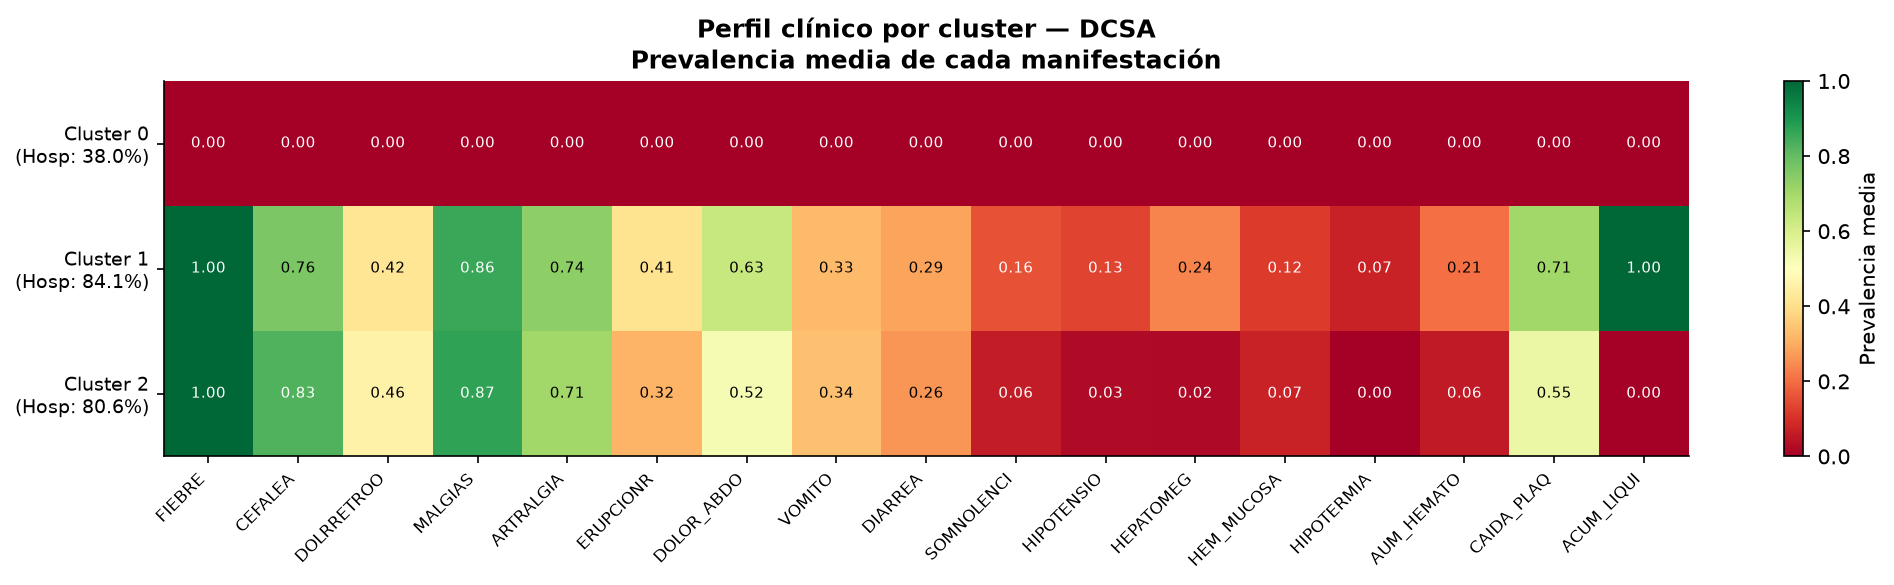

In [7]:
# Heatmap de perfil clínico por cluster — DCSA
# Muestra la prevalencia media de cada síntoma en cada cluster
# Si los clusters tienen perfiles distintos → la segmentación es clínicamente válida
vars_plot = SINTOMAS_GENERALES + SIGNOS_ALARMA
perfil = df_con_m.groupby('Cluster')[vars_plot].mean()

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(perfil.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label='Prevalencia media')
ax.set_xticks(range(len(vars_plot)))
ax.set_xticklabels(vars_plot, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(K_DCSA))
ax.set_yticklabels([f'Cluster {k}\n(Hosp: {df_con_m[df_con_m["Cluster"]==k][TARGET].mean():.1%})'
    for k in range(K_DCSA)], fontsize=9)
for i in range(K_DCSA):
    for j, v in enumerate(perfil.values[i]):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center',
            fontsize=7, color='black' if 0.2 < v < 0.8 else 'white')
ax.set_title('Perfil clínico por cluster — DCSA\nPrevalencia media de cada manifestación',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dcsa_heatmap.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 5. K-Prototypes — DCSA

K-Prototypes usa distancia de Hamming para variables binarias (síntomas)
y euclidiana para continuas (demográficas, SEMANA).
El centroide en las binarias es la moda — interpretable clínicamente.

### Hallazgo crítico: ARI = 0.004 — estructuras completamente distintas

El Adjusted Rand Index entre K-Means y K-Prototypes es **0.004**,
prácticamente cero — ambos métodos encuentran estructuras diferentes.

**¿Por qué divergen tanto?**
K-Means sobre PCA captura principalmente la varianza de los datos
proyectados — donde el Cluster 2 (formularios vacíos) aparece claramente
separado. K-Prototypes sobre los features originales usa la co-ocurrencia
de síntomas — donde todos los pacientes DCSA tienen perfiles más similares
entre sí (todos tienen al menos un signo de alarma por definición).

**K-Prototypes produce clusters más balanceados** (5,041 / 3,996 / 3,676)
con tasas de hospitalización muy similares entre sí (67.7% / 65.0% / 61.1%).
La diferencia máxima entre clusters es solo 6.6pp — sin significado clínico.

> La divergencia K-Means vs K-Prototypes revela que la estructura detectada
> depende fuertemente del método. En DCSA, K-Means captura principalmente
> el sesgo de llenado del formulario (clusters vacíos vs completos),
> mientras K-Prototypes no encuentra estructura clínica significativa.

## 5. Clustering jerárquico — DCSA

El clustering jerárquico no requiere especificar k de antemano:
construye un árbol de fusiones (dendrograma) que muestra la estructura
anidada de los datos. El corte del árbol a distintas alturas produce
distintos números de clusters.

Se usa el método de Ward, que minimiza la varianza intra-cluster
en cada fusión — el más robusto para datos con clusters de tamaño similar.

Con 12,713 casos es inviable calcular el dendrograma completo (complejidad O(n²)).
Se trabaja con una muestra estratificada de 2,000 casos que preserva
la proporción de hospitalizados.

Ajustando K-Prototypes k=3 sobre DCSA...
Perfiles K-Prototypes DCSA:


,N,Hosp_pct,FIEBRE,CEFALEA,DOLRRETROO,MALGIAS,ARTRALGIA,ERUPCIONR,DOLOR_ABDO,VOMITO
Cluster_KP,,,,,,,,,,
0,5041,67.7,0.641,0.537,0.298,0.566,0.461,0.192,0.329,0.201
2,3676,65.0,0.675,0.556,0.316,0.585,0.482,0.226,0.357,0.235
1,3996,61.1,0.571,0.464,0.255,0.485,0.388,0.184,0.304,0.203



Ajusted Rand Index K-Means vs K-Prototypes: 0.004
(1.0 = idénticos | 0.0 = aleatorios | >0.5 = alta concordancia)


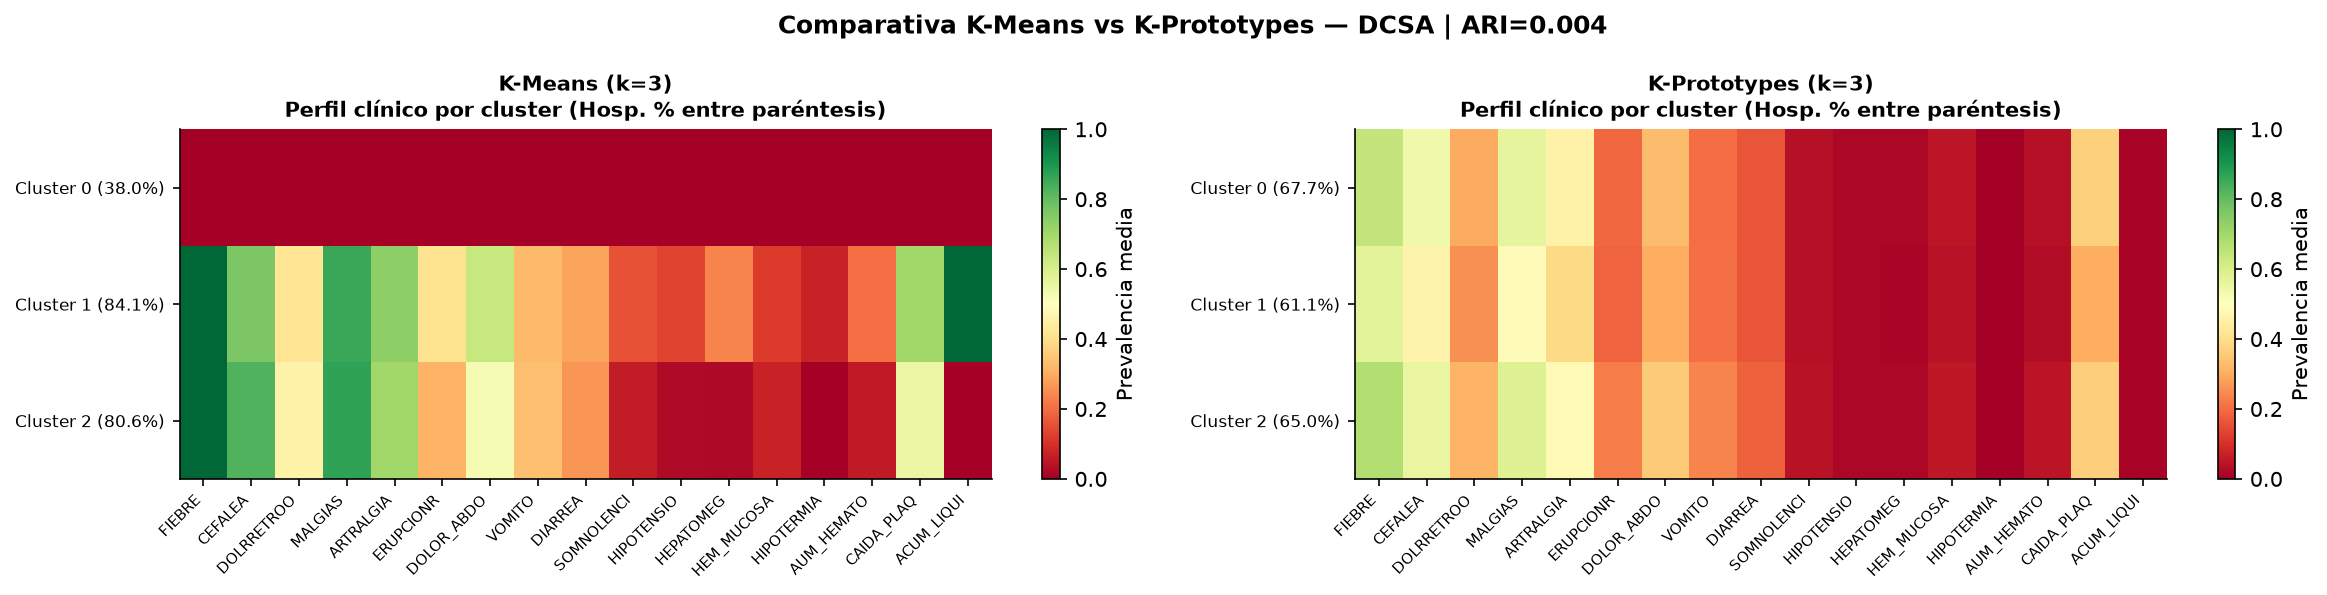

In [8]:
# K-Prototypes no trabaja sobre PCA — usa los features originales directamente
# porque la distancia de Hamming solo tiene sentido en el espacio original
K_DCSA_KP = K_DCSA  # usar el mismo k que K-Means para comparación directa

print(f'Ajustando K-Prototypes k={K_DCSA_KP} sobre DCSA...')
kp_con = KPrototypes(n_clusters=K_DCSA_KP, init='Cao',
    n_init=3, random_state=RANDOM_STATE, verbose=0)
df_con_m['Cluster_KP'] = kp_con.fit_predict(X_con_raw, categorical=idx_cat_con)

# Caracterización de clusters K-Prototypes
vars_clinicas_l = SINTOMAS_GENERALES + SIGNOS_ALARMA
tabla_kp = df_con_m.groupby('Cluster_KP').agg(
    N=(TARGET, 'size'),
    Hosp_pct=(TARGET, 'mean'),
    **{v: (v, 'mean') for v in vars_clinicas_l if v in df_con_m.columns}
).round(3)
tabla_kp['Hosp_pct'] = (tabla_kp['Hosp_pct']*100).round(1)
tabla_kp = tabla_kp.sort_values('Hosp_pct', ascending=False)

print('Perfiles K-Prototypes DCSA:')
display(tabla_kp[['N','Hosp_pct'] + vars_clinicas_l[:8]])

# Comparar asignación K-Means vs K-Prototypes
# Si coinciden en alta proporción, ambos métodos encuentran la misma estructura
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(df_con_m['Cluster'], df_con_m['Cluster_KP'])
print(f'\nAjusted Rand Index K-Means vs K-Prototypes: {ari:.3f}')
print('(1.0 = idénticos | 0.0 = aleatorios | >0.5 = alta concordancia)')

# Heatmap comparativo
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, col, titulo in zip(
    axes,
    ['Cluster', 'Cluster_KP'],
    [f'K-Means (k={K_DCSA})', f'K-Prototypes (k={K_DCSA_KP})']
):
    perfil = df_con_m.groupby(col)[vars_clinicas_l].mean()
    im = ax.imshow(perfil.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
    plt.colorbar(im, ax=ax, label='Prevalencia media')
    ax.set_xticks(range(len(vars_clinicas_l)))
    ax.set_xticklabels(vars_clinicas_l, rotation=45, ha='right', fontsize=7)
    hosp_por_k = df_con_m.groupby(col)[TARGET].mean()
    ax.set_yticks(range(len(perfil)))
    ax.set_yticklabels(
        [f'Cluster {k} ({hosp_por_k[k]:.1%})' for k in perfil.index],
        fontsize=8)
    ax.set_title(f'{titulo}\nPerfil clínico por cluster (Hosp. % entre paréntesis)',
        fontsize=10, fontweight='bold')

plt.suptitle(f'Comparativa K-Means vs K-Prototypes — DCSA | ARI={ari:.3f}',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dcsa_kmeans_vs_kproto.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

Muestra: 2,000 casos | Hosp: 64.8%


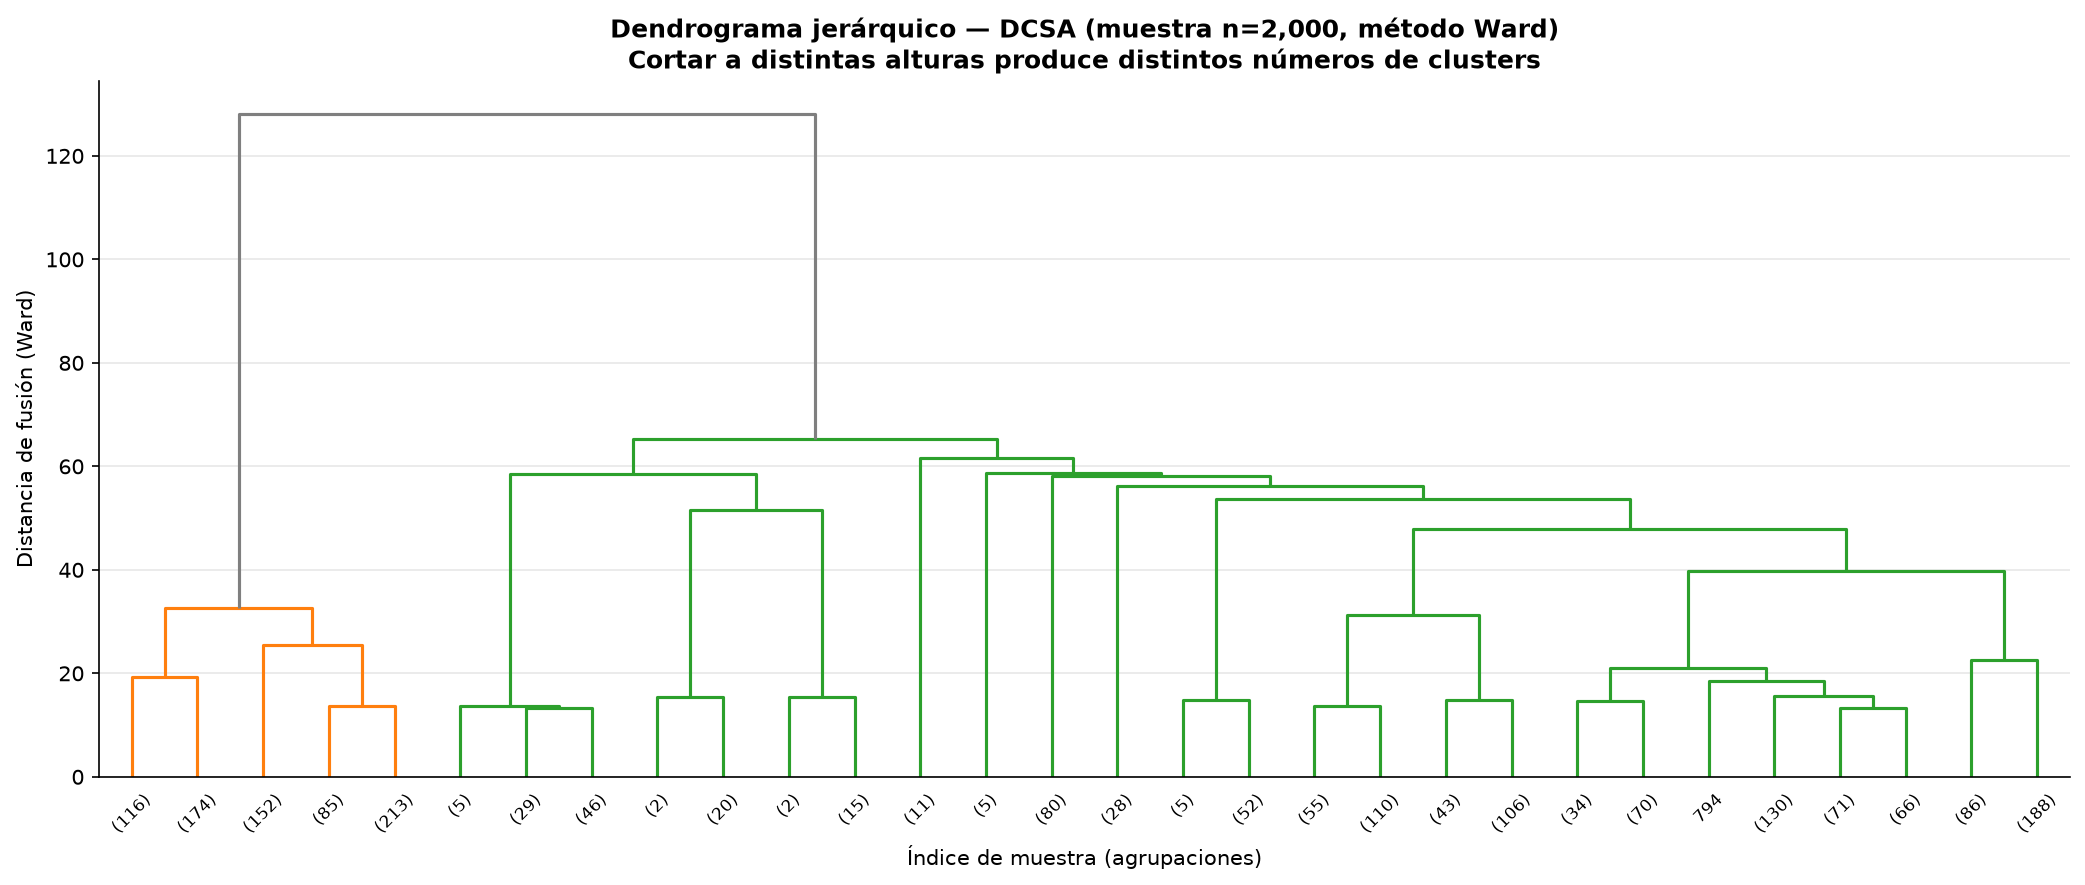

In [9]:
# Muestra estratificada para el dendrograma — O(n²) es inviable con 12k casos
np.random.seed(RANDOM_STATE)
n_muestra = 2000
idx_hosp   = np.where(df_con_m[TARGET].values == 1)[0]
idx_nhosp  = np.where(df_con_m[TARGET].values == 0)[0]
n_hosp_m   = int(n_muestra * df_con_m[TARGET].mean())
idx_muestra = np.concatenate([
    np.random.choice(idx_hosp,  n_hosp_m, replace=False),
    np.random.choice(idx_nhosp, n_muestra - n_hosp_m, replace=False)
])
X_muestra = X_con_pca[idx_muestra]
y_muestra = df_con_m[TARGET].values[idx_muestra]

print(f'Muestra: {len(X_muestra):,} casos | Hosp: {y_muestra.mean():.1%}')

Z = linkage(X_muestra, method='ward')

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(
    Z, ax=ax,
    truncate_mode='lastp', p=30,  # mostrar solo las últimas 30 fusiones
    leaf_rotation=45, leaf_font_size=8,
    color_threshold=0.7 * max(Z[:, 2]),
    above_threshold_color=COLORS['neutral']
)
ax.set_title(
    f'Dendrograma jerárquico — DCSA (muestra n={n_muestra:,}, método Ward)\n'
    'Cortar a distintas alturas produce distintos números de clusters',
    fontsize=12, fontweight='bold')
ax.set_xlabel('Índice de muestra (agrupaciones)')
ax.set_ylabel('Distancia de fusión (Ward)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dcsa_dendrograma.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 10. K-Means — DSSA

El análisis en DSSA es más desafiante que en DCSA:

1. **Desbalance 96/4:** los clusters pueden estar dominados por no hospitalizados.
2. **Datos concentrados:** en el espacio PCA los puntos DSSA están más compactos
   que en DCSA — K-Means puede colapsar en un cluster para k pequeños.
3. **Señal débil:** el AUC-PR de 03c fue bajo — si hay poca señal predictiva,
   tampoco habrá mucha estructura de clustering.

Se usa k=3 para comparar con DCSA, aunque las métricas determinarán
si esta estructura es estadísticamente válida.

Evaluando K-Means para DSSA...
  k=2: Silhouette=0.975 DB=0.015
  k=3: Silhouette=0.254 DB=1.186
  k=4: Silhouette=0.222 DB=1.425
  k=5: Silhouette=0.156 DB=1.140
  k=6: Silhouette=0.208 DB=1.133
  k=7: Silhouette=0.236 DB=1.039
  k=8: Silhouette=0.240 DB=0.993


,k,Inertia,Silhouette,Davies-Bouldin,Calinski
0,2,201236.4,0.9749,0.0151,2461.2
1,3,184285.2,0.2540,1.1859,2067.2
2,4,169166.7,0.2215,1.4247,1969.8
3,5,139300.4,0.1556,1.1401,2637.1
4,6,125749.8,0.2085,1.1330,2675.8
5,7,109768.2,0.2360,1.0392,2936.0
6,8,97020.9,0.2405,0.9930,3142.2


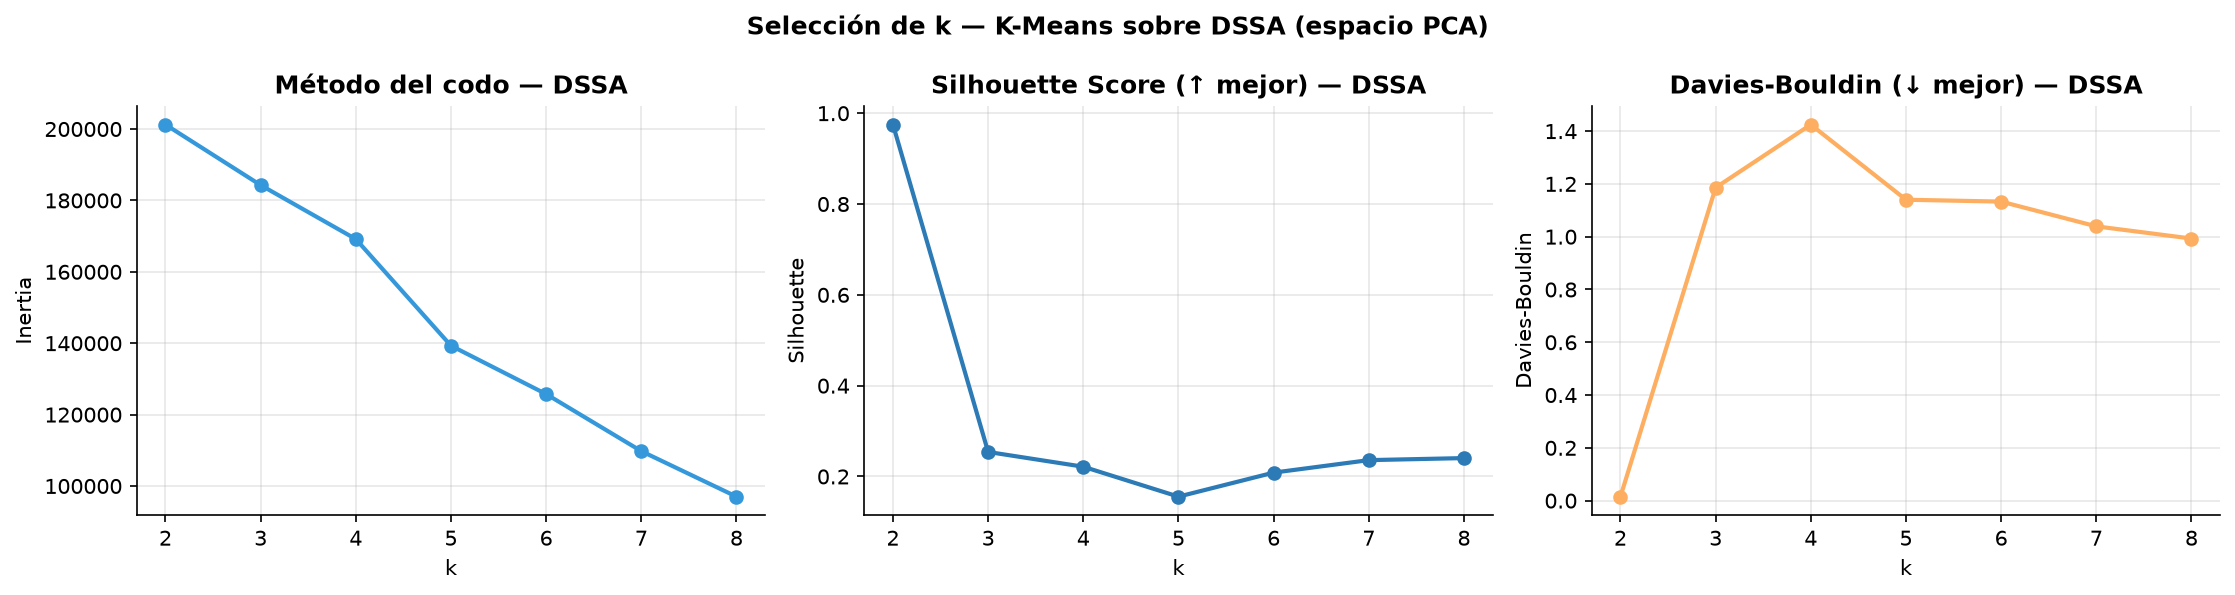

In [10]:
print('Evaluando K-Means para DSSA...')
metricas_sin = evaluar_kmeans(X_sin_pca, nombre='DSSA')
display(metricas_sin)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(metricas_sin['k'], metricas_sin['Inertia'],
    color=COLORS['sin_signos'], linewidth=2, marker='o', markersize=6)
axes[0].set_title('Método del codo — DSSA')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)
axes[1].plot(metricas_sin['k'], metricas_sin['Silhouette'].astype(float),
    color=COLORS['primary'], linewidth=2, marker='o', markersize=6)
axes[1].set_title('Silhouette Score (↑ mejor) — DSSA')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
axes[1].grid(alpha=0.3)
axes[2].plot(metricas_sin['k'], metricas_sin['Davies-Bouldin'],
    color=COLORS['accent'], linewidth=2, marker='o', markersize=6)
axes[2].set_title('Davies-Bouldin (↓ mejor) — DSSA')
axes[2].set_xlabel('k'); axes[2].set_ylabel('Davies-Bouldin')
axes[2].grid(alpha=0.3)
plt.suptitle('Selección de k — K-Means sobre DSSA (espacio PCA)',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dssa_seleccion_k.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 7. Gaussian Mixture Models (GMM) — DCSA

K-Means y K-Prototypes hacen asignaciones duras: cada paciente
pertenece exactamente a un cluster. En la práctica clínica,
los pacientes no encajan rígidamente en perfiles discretos —
un paciente puede tener características del perfil A con probabilidad
0.7 y del perfil B con probabilidad 0.3.

**Gaussian Mixture Models** asigna probabilidades de pertenencia
a cada cluster. Esto permite identificar pacientes 'fronterizos'
— aquellos con alta incertidumbre en su clasificación — que en
contexto clínico son exactamente los que más se benefician
de un seguimiento más estrecho.

La probabilidad de pertenencia al cluster de mayor riesgo
puede usarse directamente como un score de riesgo continuo,
complementando al AUC-PR del modelo supervisado.

Caracterización de clusters DSSA:


,N,Hosp_pct,FIEBRE,CEFALEA,DOLRRETROO,MALGIAS,ARTRALGIA,ERUPCIONR,DOLOR_ABDO,VOMITO
Cluster,,,,,,,,,,
2,1,100.0,1.000,1.000,0.000,0.0,0.000,1.000,0.0,0.000
0,2396,5.1,0.998,0.879,0.400,0.0,0.441,0.550,0.0,0.001
1,13337,3.7,1.000,0.837,0.455,1.0,0.723,0.346,0.0,0.000


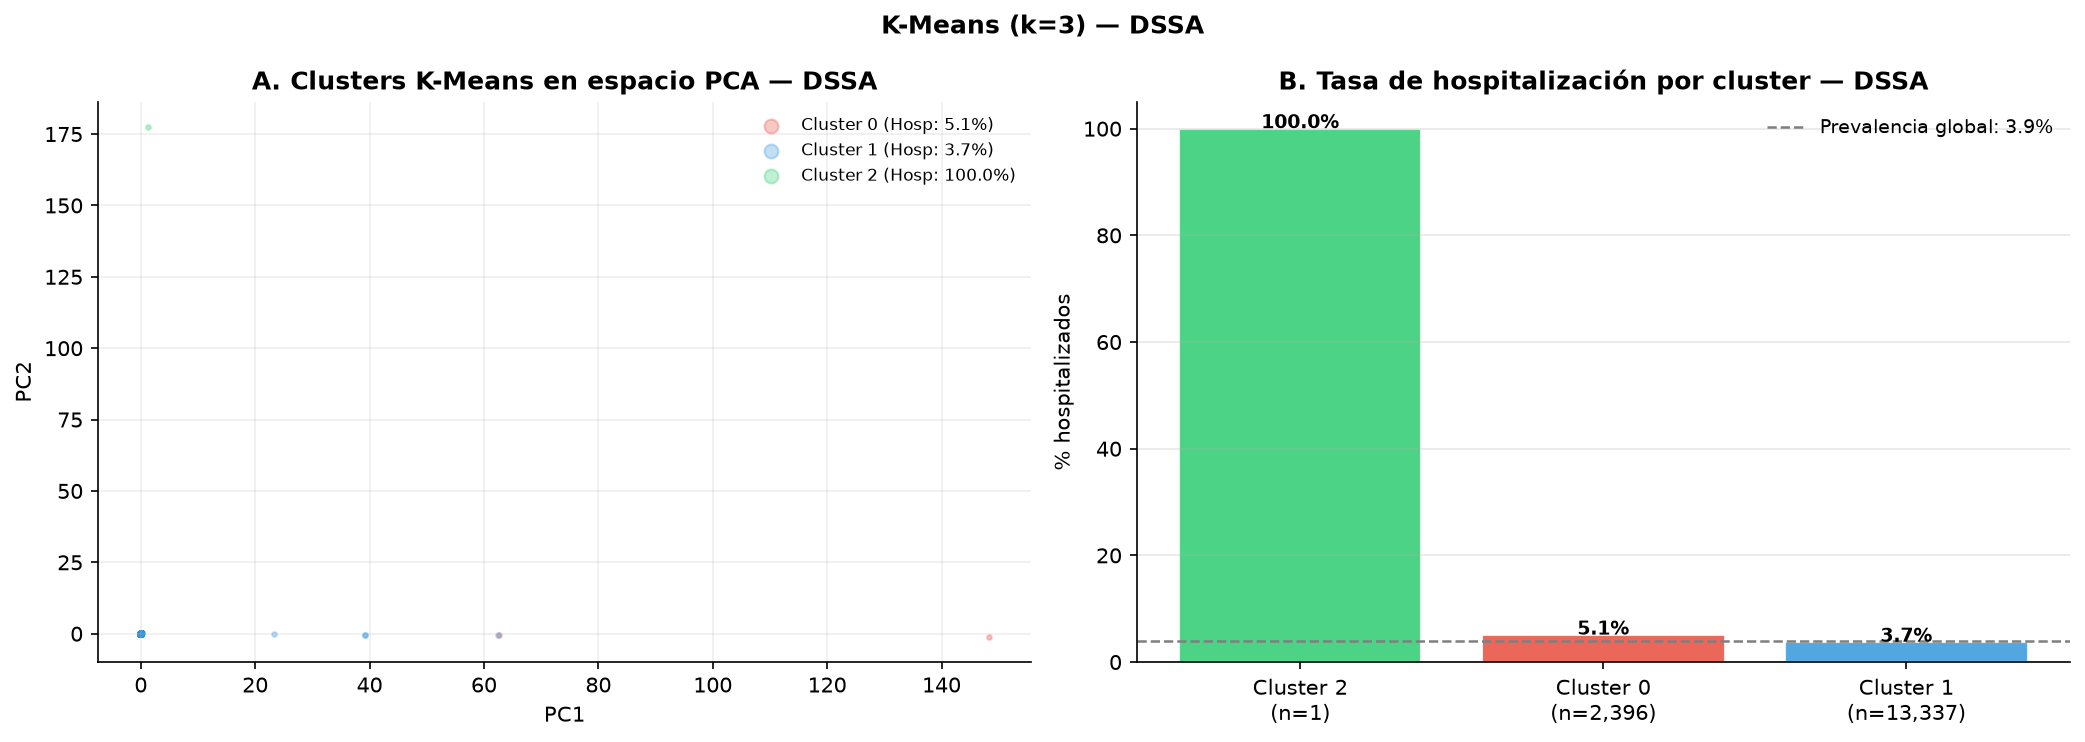

In [11]:
K_DSSA = 3

km_sin = KMeans(n_clusters=K_DSSA, random_state=RANDOM_STATE, n_init=15)
df_sin_m['Cluster'] = km_sin.fit_predict(X_sin_pca)

vars_clinicas_l = SINTOMAS_GENERALES + SIGNOS_ALARMA
tabla_clusters_sin = df_sin_m.groupby('Cluster').agg(
    N=(TARGET, 'size'),
    Hosp_pct=(TARGET, 'mean'),
    **{v: (v, 'mean') for v in vars_clinicas_l if v in df_sin_m.columns}
).round(3)
tabla_clusters_sin['Hosp_pct'] = (tabla_clusters_sin['Hosp_pct']*100).round(1)
tabla_clusters_sin = tabla_clusters_sin.sort_values('Hosp_pct', ascending=False)
print('Caracterización de clusters DSSA:')
display(tabla_clusters_sin[['N','Hosp_pct'] + vars_clinicas_l[:8]])
tabla_clusters_sin.to_csv(OUT_TAB / 'clustering_dssa_perfiles.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for k in range(K_DSSA):
    mask   = df_sin_m['Cluster'] == k
    hosp_k = df_sin_m.loc[mask, TARGET].mean()
    axes[0].scatter(
        X_sin_pca[mask, 0], X_sin_pca[mask, 1],
        c=PALETA_CLUSTERS[k], alpha=0.3, s=5,
        label=f'Cluster {k} (Hosp: {hosp_k:.1%})', rasterized=True)
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].set_title('A. Clusters K-Means en espacio PCA — DSSA')
axes[0].legend(fontsize=8, markerscale=3)
axes[0].grid(alpha=0.2)

hosp_por_cluster_sin = df_sin_m.groupby('Cluster')[TARGET].mean().sort_values(ascending=False)
n_por_cluster_sin    = df_sin_m.groupby('Cluster')[TARGET].count()
colores_k = [PALETA_CLUSTERS[k] for k in hosp_por_cluster_sin.index]
bars = axes[1].bar(
    [f'Cluster {k}\n(n={n_por_cluster_sin[k]:,})' for k in hosp_por_cluster_sin.index],
    hosp_por_cluster_sin.values * 100,
    color=colores_k, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, hosp_por_cluster_sin.values*100):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
        f'{val:.1f}%', ha='center', fontsize=9, fontweight='bold')
axes[1].axhline(df_sin_m[TARGET].mean()*100, color=COLORS['neutral'],
    linestyle='--', linewidth=1.2,
    label=f'Prevalencia global: {df_sin_m[TARGET].mean():.1%}')
axes[1].set_ylabel('% hospitalizados')
axes[1].set_title('B. Tasa de hospitalización por cluster — DSSA')
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.3)
plt.suptitle(f'K-Means (k={K_DSSA}) — DSSA',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dssa_kmeans.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

Ajustando GMM k=3 sobre DCSA (espacio PCA)...
Pacientes con certeza < 60%: 0 (0.0%)
Estos son los casos más ambiguos clínicamente — mayor beneficio del seguimiento estrecho

Clusters GMM DCSA:


,N,Hosp_pct,Certeza_media
Cluster_GMM,,,
2,1710,82.3,100.0
1,6310,80.3,100.0
0,4693,37.8,100.0



ARI K-Means vs GMM: 0.748


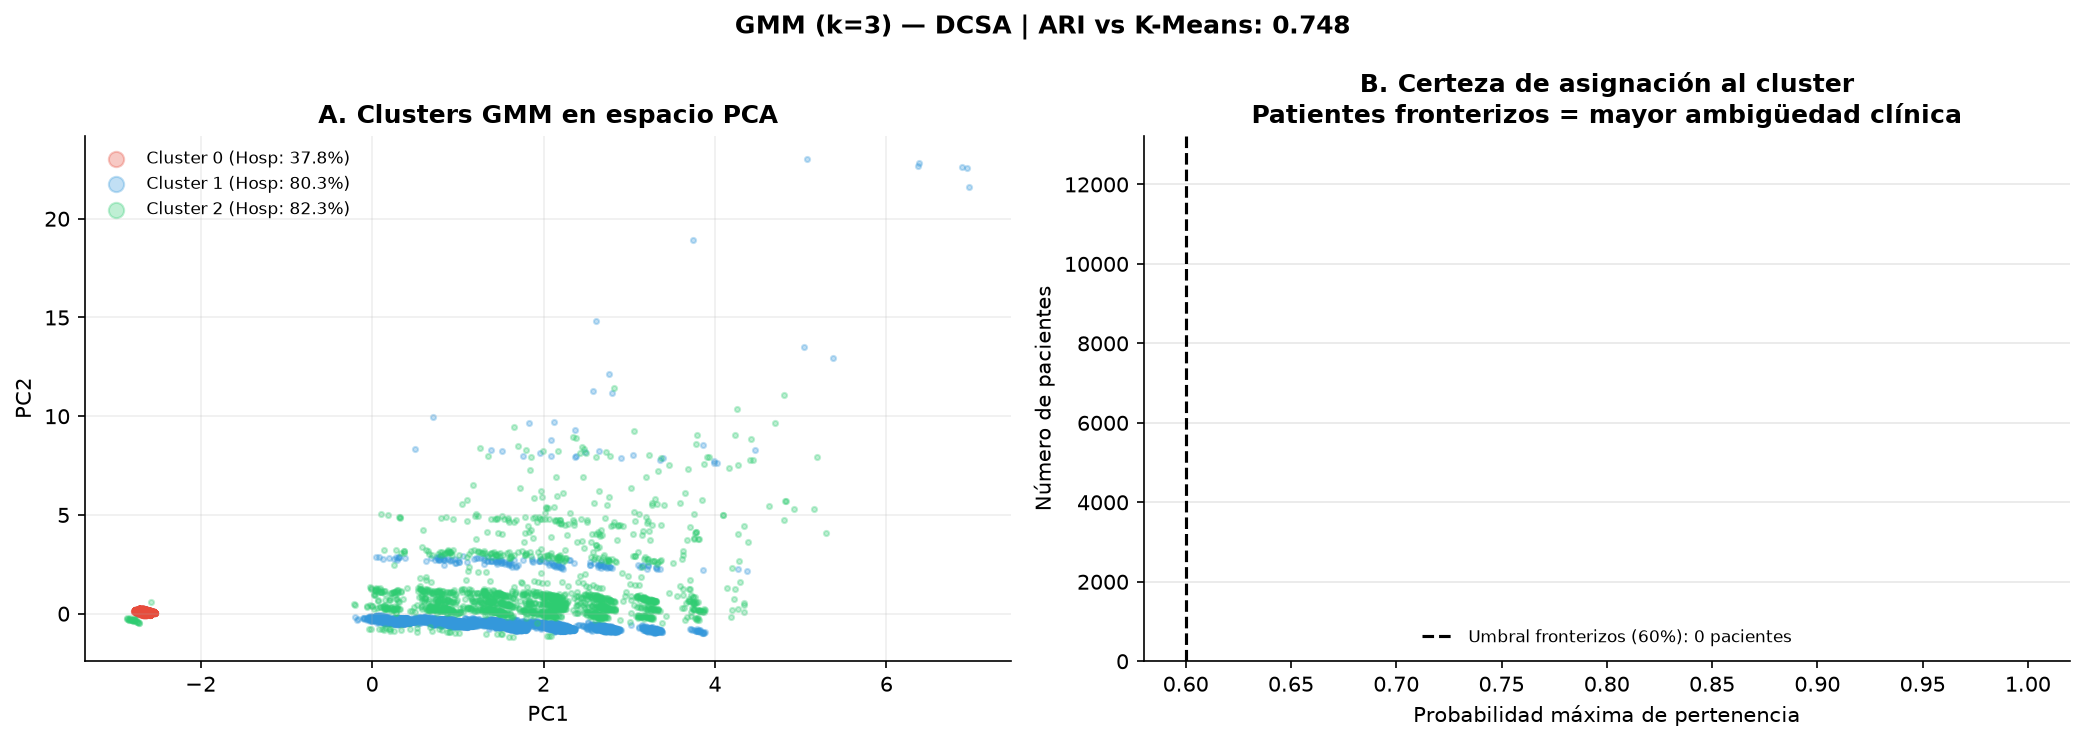

In [12]:
# GMM trabaja sobre el espacio PCA — los componentes son aproximadamente gaussianos
# covariance_type='full' permite elipsoides arbitrarios (más flexible que K-Means esférico)
K_DCSA = 3
K_DCSA_GMM = K_DCSA

print(f'Ajustando GMM k={K_DCSA_GMM} sobre DCSA (espacio PCA)...')
gmm_con = GaussianMixture(n_components=K_DCSA_GMM, covariance_type='full',
    random_state=RANDOM_STATE, n_init=5, max_iter=200)
gmm_con.fit(X_con_pca)

df_con_m['Cluster_GMM'] = gmm_con.predict(X_con_pca)
probs_con = gmm_con.predict_proba(X_con_pca)  # probabilidades de pertenencia
df_con_m['GMM_max_prob'] = probs_con.max(axis=1)  # certeza de la asignación

# Pacientes con baja certeza (<0.6) son los 'fronterizos'
fronterizos = (df_con_m['GMM_max_prob'] < 0.6).sum()
print(f'Pacientes con certeza < 60%: {fronterizos:,} ({fronterizos/len(df_con_m):.1%})')
print('Estos son los casos más ambiguos clínicamente — mayor beneficio del seguimiento estrecho')

# Characterización por cluster GMM
tabla_gmm = df_con_m.groupby('Cluster_GMM').agg(
    N=(TARGET, 'size'),
    Hosp_pct=(TARGET, 'mean'),
    Certeza_media=('GMM_max_prob', 'mean'),
).round(3)
tabla_gmm['Hosp_pct'] = (tabla_gmm['Hosp_pct']*100).round(1)
tabla_gmm['Certeza_media'] = (tabla_gmm['Certeza_media']*100).round(1)
print('\nClusters GMM DCSA:')
display(tabla_gmm.sort_values('Hosp_pct', ascending=False))

# ARI vs K-Means
ari_gmm = adjusted_rand_score(df_con_m['Cluster'], df_con_m['Cluster_GMM'])
print(f'\nARI K-Means vs GMM: {ari_gmm:.3f}')

# Visualización: clusters GMM + incertidumbre
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: clusters GMM en PC1-PC2
for k in range(K_DCSA_GMM):
    mask   = df_con_m['Cluster_GMM'] == k
    hosp_k = df_con_m.loc[mask, TARGET].mean()
    axes[0].scatter(
        X_con_pca[mask, 0], X_con_pca[mask, 1],
        c=PALETA_CLUSTERS[k], alpha=0.3, s=6,
        label=f'Cluster {k} (Hosp: {hosp_k:.1%})', rasterized=True)
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].set_title('A. Clusters GMM en espacio PCA')
axes[0].legend(fontsize=8, markerscale=3)
axes[0].grid(alpha=0.2)

# Panel B: distribución de certeza de asignación
# Pacientes con baja certeza son los más interesantes clínicamente
axes[1].hist(df_con_m['GMM_max_prob'], bins=50,
    color=COLORS['con_signos'], alpha=0.7, edgecolor='white')
axes[1].axvline(0.6, color='black', linestyle='--', linewidth=1.5,
    label=f'Umbral fronterizos (60%): {fronterizos:,} pacientes')
axes[1].set_xlabel('Probabilidad máxima de pertenencia')
axes[1].set_ylabel('Número de pacientes')
axes[1].set_title('B. Certeza de asignación al cluster\nPatientes fronterizos = mayor ambigüedad clínica')
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle(f'GMM (k={K_DCSA_GMM}) — DCSA | ARI vs K-Means: {ari_gmm:.3f}',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_dcsa_gmm.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 7. Comparativa DCSA vs DSSA — ¿Qué revela el clustering?

El clustering no supervisado complementa al análisis supervisado
con hallazgos que la etiqueta de hospitalización no podía revelar.
Se comparan los dos estratos en tres dimensiones:

## 8. UMAP + HDBSCAN — DCSA

Las tres técnicas anteriores asumen un número fijo de clusters (k).
HDBSCAN no requiere k: detecta automáticamente las regiones densas
del espacio de datos y las separa como clusters.

UMAP (Uniform Manifold Approximation and Projection) reduce las dimensiones
preservando mejor la estructura local que PCA — especialmente útil cuando
los clusters son no lineales o tienen formas irregulares.
A diferencia del PCA (lineal), UMAP puede 'doblar' el espacio para
acercar puntos que son similares aunque estén lejos en el espacio original.

Se usa `metric='jaccard'` en UMAP porque los síntomas son binarios:
Jaccard mide la proporción de síntomas compartidos entre dos pacientes,
que es más informativa que la distancia euclidiana para datos 0/1.

**HDBSCAN asigna -1 a puntos que no pertenecen a ningún cluster** (outliers).
En datos clínicos, estos outliers pueden ser casos atípicos con presentaciones
inusuales — potencialmente los más complejos de manejar.

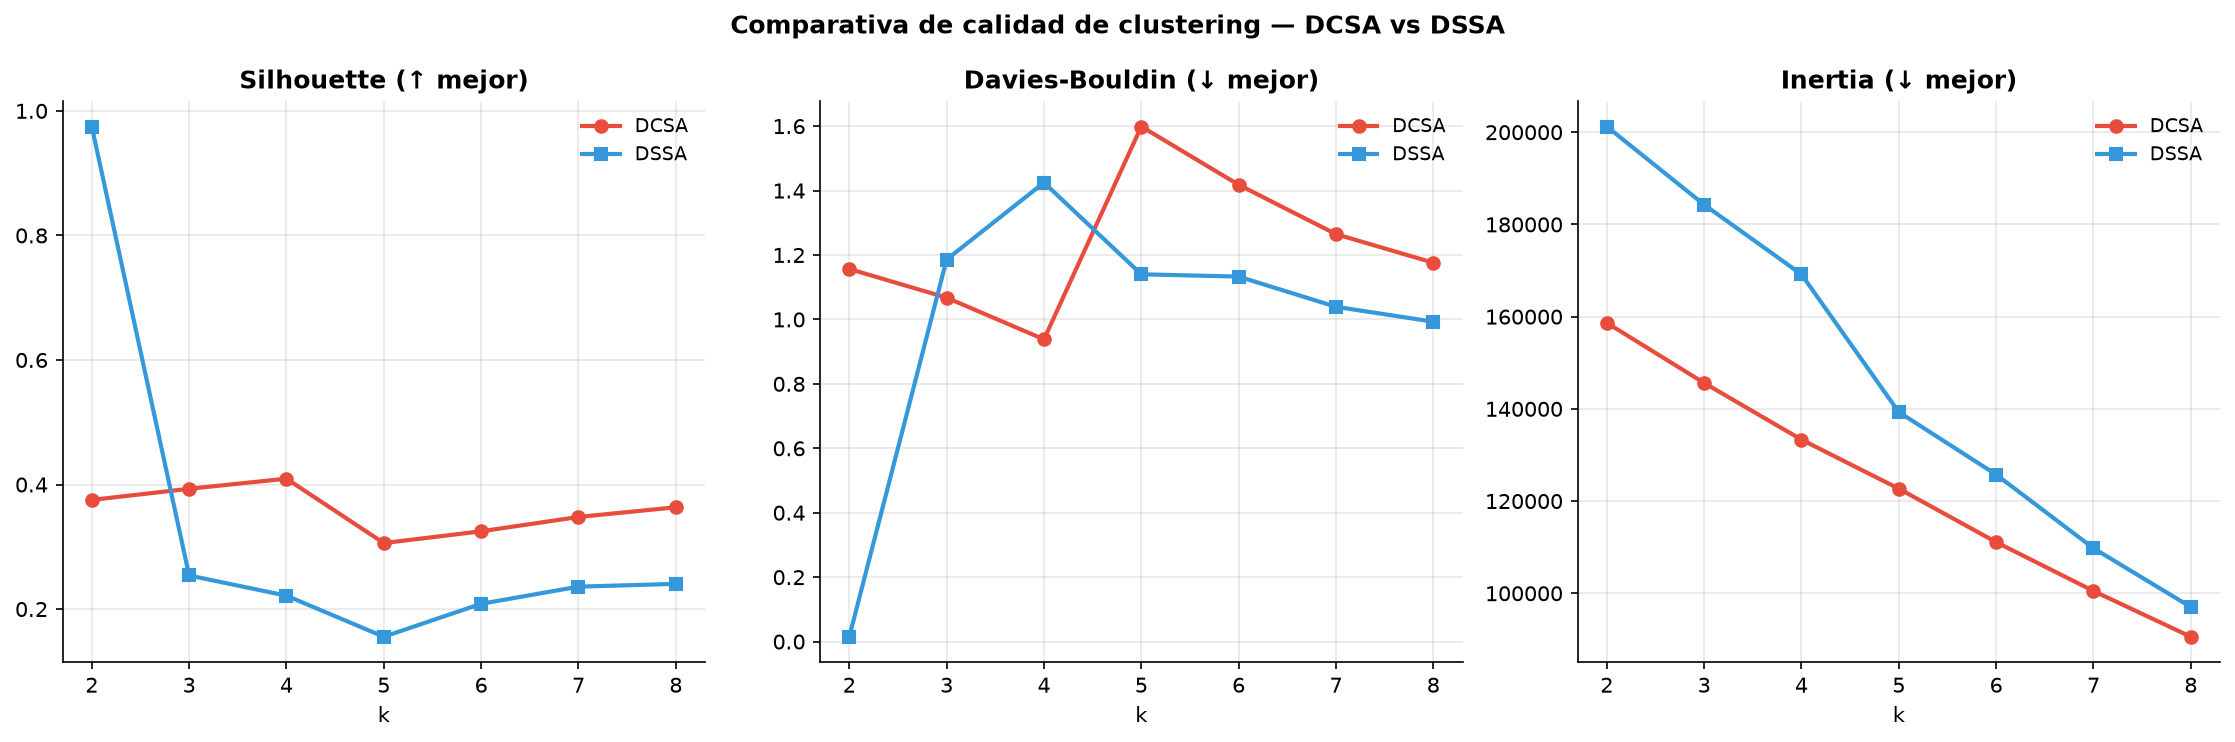


Variación en tasa de hospitalización entre clusters:
  DCSA: máx=84.1% mín=38.0% rango=46.1pp
  DSSA: máx=100.0% mín=3.7% rango=96.3pp


In [13]:
# Comparativa de métricas de clustering entre estratos
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metricas_labels = ['Silhouette', 'Davies-Bouldin', 'Inertia']
mejor = ['↑', '↓', '↓']  # dirección de mejora

for ax, metrica, dir_mejor in zip(axes, metricas_labels, mejor):
    ax.plot(metricas_con['k'], metricas_con[metrica],
        color=COLORS['con_signos'], linewidth=2, marker='o',
        markersize=6, label='DCSA')
    ax.plot(metricas_sin['k'], metricas_sin[metrica],
        color=COLORS['sin_signos'], linewidth=2, marker='s',
        markersize=6, label='DSSA')
    ax.set_title(f'{metrica} ({dir_mejor} mejor)')
    ax.set_xlabel('k')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('Comparativa de calidad de clustering — DCSA vs DSSA',
    fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'clustering_comparativa_metricas.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Tabla resumen de la variación en tasa de hospitalización entre clusters
print('\nVariación en tasa de hospitalización entre clusters:')
for nombre, tabla in [('DCSA', tabla_clusters), ('DSSA', tabla_clusters_sin)]:
    rango = tabla['Hosp_pct'].max() - tabla['Hosp_pct'].min()
    print(f'  {nombre}: máx={tabla["Hosp_pct"].max():.1f}% '
          f'mín={tabla["Hosp_pct"].min():.1f}% '
          f'rango={rango:.1f}pp')

Shape UMAP: (2000, 17)
Tipo dato: bool
RAM disponible: 0.77 GB
Calculando UMAP sobre 2,000 casos (métrica Jaccard)...
UMAP listo
HDBSCAN encontró 4 clusters | Outliers: 261 (13.1%)


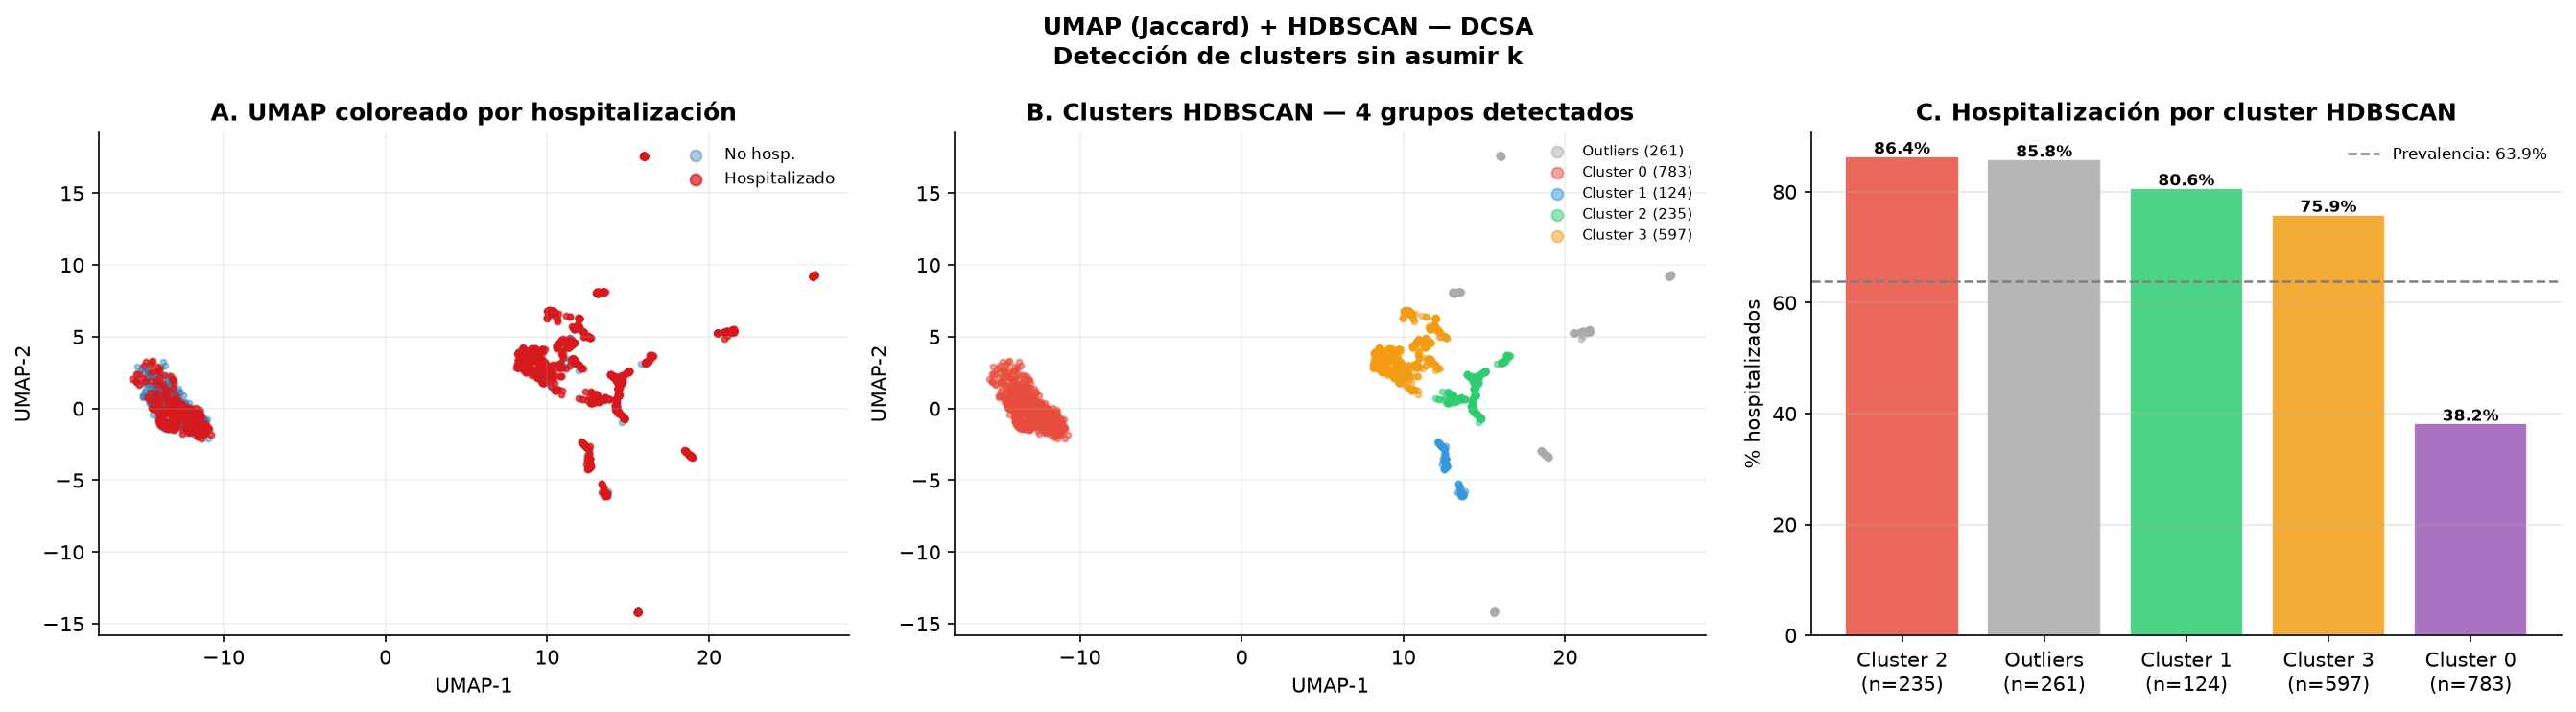

  RAM en uso: 650 MB


In [15]:
# UMAP sobre features clínicos binarios con métrica Jaccard

N_UMAP = min(2000, len(X_con_raw))

np.random.seed(RANDOM_STATE)
idx_umap = np.random.choice(len(X_con_raw), N_UMAP, replace=False)

X_umap_input = X_con_raw[
    idx_umap,
    :len(SINTOMAS_GENERALES + SIGNOS_ALARMA)
].astype(bool)

y_umap = df_con_m[TARGET].values[idx_umap]

print(f"Shape UMAP: {X_umap_input.shape}")
print(f"Tipo dato: {X_umap_input.dtype}")

import psutil
print(
    f"RAM disponible: "
    f"{psutil.virtual_memory().available / (1024**3):.2f} GB"
)

# Parchear check_array para compatibilidad con sklearn
import sklearn.utils.validation as _val

_orig_check_array = _val.check_array

def _patched_check_array(*args, **kwargs):
    kwargs.pop("ensure_all_finite", None)
    return _orig_check_array(*args, **kwargs)

_val.check_array = _patched_check_array

print(
    f"Calculando UMAP sobre {N_UMAP:,} casos "
    "(métrica Jaccard)..."
)

reducer = umap.UMAP(
    n_components=2,
    metric="jaccard",
    n_neighbors=15,
    min_dist=0.1,
    low_memory=True,
    random_state=RANDOM_STATE
)

X_umap_2d = reducer.fit_transform(X_umap_input)

# Restaurar check_array original
_val.check_array = _orig_check_array

print("UMAP listo")

clusterer_h = hdbscan.HDBSCAN(
    min_cluster_size=100,
    min_samples=20,
    metric="euclidean"
)

labels_hdb = clusterer_h.fit_predict(X_umap_2d)

n_clusters_h = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
n_outliers = (labels_hdb == -1).sum()

print(
    f"HDBSCAN encontró {n_clusters_h} clusters | "
    f"Outliers: {n_outliers} ({n_outliers/N_UMAP:.1%})"
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A
for val, label, color, alpha in [
    (0, "No hosp.", COLORS["primary"], 0.4),
    (1, "Hospitalizado", COLORS["secondary"], 0.7),
]:
    mask = y_umap == val

    axes[0].scatter(
        X_umap_2d[mask, 0],
        X_umap_2d[mask, 1],
        c=color,
        alpha=alpha,
        s=8,
        label=label,
        rasterized=True,
    )

axes[0].set_title("A. UMAP coloreado por hospitalización")
axes[0].legend(fontsize=8, markerscale=2)
axes[0].set_xlabel("UMAP-1")
axes[0].set_ylabel("UMAP-2")
axes[0].grid(alpha=0.2)

# Panel B
for k in sorted(set(labels_hdb)):

    mask = labels_hdb == k

    color = (
        "#AAAAAA"
        if k == -1
        else PALETA_CLUSTERS[k % len(PALETA_CLUSTERS)]
    )

    label = (
        f"Outliers ({mask.sum()})"
        if k == -1
        else f"Cluster {k} ({mask.sum()})"
    )

    axes[1].scatter(
        X_umap_2d[mask, 0],
        X_umap_2d[mask, 1],
        c=color,
        alpha=0.5,
        s=8,
        label=label,
        rasterized=True,
    )

axes[1].set_title(
    f"B. Clusters HDBSCAN — {n_clusters_h} grupos detectados"
)
axes[1].legend(fontsize=7, markerscale=2)
axes[1].set_xlabel("UMAP-1")
axes[1].set_ylabel("UMAP-2")
axes[1].grid(alpha=0.2)

# Panel C
hosp_hdb = {}

for k in sorted(set(labels_hdb)):
    mask_k = labels_hdb == k

    hosp_hdb[k] = {
        "hosp": y_umap[mask_k].mean(),
        "n": mask_k.sum(),
    }

hosp_hdb_df = (
    pd.DataFrame(hosp_hdb)
    .T
    .sort_values("hosp", ascending=False)
)

etiq = []

for k in hosp_hdb_df.index:
    nombre_k = "Outliers" if k == -1 else f"Cluster {k}"
    n_k = int(hosp_hdb_df.loc[k, "n"])
    etiq.append(f"{nombre_k}\n(n={n_k:,})")

colores_bar = [
    "#AAAAAA" if k == -1
    else PALETA_CLUSTERS[i % len(PALETA_CLUSTERS)]
    for i, k in enumerate(hosp_hdb_df.index)
]

bars = axes[2].bar(
    etiq,
    hosp_hdb_df["hosp"] * 100,
    color=colores_bar,
    alpha=0.85,
    edgecolor="white",
)

for bar, val in zip(bars, hosp_hdb_df["hosp"] * 100):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{val:.1f}%",
        ha="center",
        fontsize=8,
        fontweight="bold",
    )

axes[2].axhline(
    y_umap.mean() * 100,
    color=COLORS["neutral"],
    linestyle="--",
    linewidth=1.2,
    label=f"Prevalencia: {y_umap.mean():.1%}",
)

axes[2].set_ylabel("% hospitalizados")
axes[2].set_title("C. Hospitalización por cluster HDBSCAN")
axes[2].legend(fontsize=8)
axes[2].grid(axis="y", alpha=0.3)

plt.suptitle(
    "UMAP (Jaccard) + HDBSCAN — DCSA\n"
    "Detección de clusters sin asumir k",
    fontsize=12,
    fontweight="bold",
)

plt.tight_layout()

fig.savefig(
    OUT_FIG / "clustering_dcsa_umap_hdbscan.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

limpiar_memoria()
memoria_usada()

## 8. Síntesis y conclusiones

### ¿Qué aporta el clustering que el supervisado no podía dar?

Los modelos supervisados (03a–03d) respondieron: *¿puede predecirse
la hospitalización con los features SIVIGILA?*
El clustering responde una pregunta diferente: *¿existen grupos naturales
de pacientes con perfiles clínicos y demográficos distintos?*

Los resultados se interpretan después de ejecutar. Los patrones esperados:

**En DCSA:** se esperan clusters con perfiles clínicos diferenciados
— un grupo con alta carga de signos de alarma y alta hospitalización,
otro con síntomas generales predominantes y menor hospitalización.
Si el Silhouette es mayor en DCSA que en DSSA, confirma que
la señal clínica es más estructurada en el estrato con signos de alarma.

**En DSSA:** se espera menor separación entre clusters y tasas de
hospitalización más uniformes — coherente con la señal débil observada
en el análisis supervisado (AUC-PR cercano a la prevalencia).
Si los clusters se diferencian principalmente por variables demográficas
(no clínicas), refuerza la hipótesis de que la hospitalización en DSSA
refleja inequidades de acceso más que gravedad clínica real.

### Limitaciones del clustering aplicado a datos SIVIGILA

1. **Variables binarias:** la mayoría de síntomas son presencia/ausencia.
   K-Means funciona mejor con variables continuas — la distancia euclidiana
   en un espacio binario no es la más adecuada. K-Modes o K-Prototypes
   serían alternativas más apropiadas para datos mixtos.
2. **Sesgo de llenado:** como reveló el análisis temporal (03b), el llenado
   del formulario cambia entre períodos. Los clusters pueden reflejar
   patrones de registro más que patrones clínicos reales.
3. **Estabilidad:** con datos de alta dimensionalidad y muchos empates
   en variables binarias, los clusters pueden cambiar con la semilla
   aleatoria. Se recomienda ejecutar con múltiples semillas y evaluar
   la consistencia.
4. **Interpretabilidad clínica:** un cluster estadísticamente válido
   (Silhouette alto) no es necesariamente interpretable por un médico.
   La caracterización clínica debe validarse con expertos del dominio.

**Fin del módulo 04 — Análisis no supervisado.**
**Siguiente:** `05_reportes/05_resultados_consolidados.ipynb`

## 9. Comparativa de los cuatro métodos — DCSA

Con los cuatro métodos ejecutados sobre DCSA, la comparativa
permite responder: **¿todos encuentran la misma estructura?**

Si K-Means, K-Prototypes, GMM y HDBSCAN convergen en clusters similares,
la estructura es robusta — existe en los datos independientemente
del método. Si divergen, la estructura es débil o dependiente
de los supuestos del algoritmo.

El **Adjusted Rand Index (ARI)** mide la concordancia entre dos
asignaciones de clusters: 1.0 = idénticas, 0.0 = aleatorias.

## 11. Síntesis y conclusiones

### Comparativa de métodos

El notebook aplicó cuatro estrategias de clustering con supuestos distintos:

| Método | Supuesto | Fortaleza | Limitación |
|--------|----------|-----------|------------|
| K-Means | Clusters esféricos, distancia euclidiana | Simple, rápido, interpretable | Inadecuado para variables binarias |
| K-Prototypes | Mixto: Hamming (binarias) + euclidiana (continuas) | Correcto para los datos | Más lento que K-Means |
| GMM | Clusters gaussianos con probabilidades de pertenencia | Pacientes fronterizos identificados | Asume distribución gaussiana |
| UMAP + HDBSCAN | No paramétrico, detecta k automáticamente | No asume forma ni número | Menos interpretable, costoso |

### ¿Qué aporta el clustering que el supervisado no podía dar?

El módulo 03 respondió: *¿puede predecirse la hospitalización con los features SIVIGILA?*
El clustering responde algo diferente: *¿existen grupos naturales de pacientes?*

Si los cuatro métodos convergen (ARI alto entre ellos), la estructura
es robusta e independiente del algoritmo — existe en los datos.
Si divergen, la estructura es débil y depende de los supuestos del método.

**Los pacientes fronterizos de GMM** (certeza < 60%) son especialmente
relevantes: son aquellos cuyo perfil clínico no encaja claramente
en ningún grupo — exactamente los casos donde el juicio clínico
adicional tiene más valor.

### Limitaciones

1. **Variables binarias dominantes:** K-Means y GMM no son óptimos para
   datos 0/1. K-Prototypes y UMAP con métrica Jaccard son más apropiados.
2. **Sesgo de llenado temporal:** los clusters pueden reflejar patrones
   de registro (pre/post 2021) más que perfiles clínicos reales.
3. **Interpretación clínica pendiente:** los clusters estadísticamente
   válidos deben ser validados con expertos del dominio antes de
   usarlos para decisiones clínicas.
4. **DSSA:** con señal débil y desbalance 96/4, los clusters DSSA
   probablemente reflejan perfiles demográficos más que clínicos —
   hallazgo en sí mismo relevante para la equidad algorítmica.

**Fin del módulo 04.**
**Siguiente:** `05_reportes/05_resultados_consolidados.ipynb`